In [1]:
%load_ext autoreload
%autoreload 2
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams.update({'errorbar.capsize': 3})
plt.rcParams['xtick.labelsize']= 13
plt.rcParams['ytick.labelsize']= 13
plt.rcParams.update({'axes.labelsize': 16})

In [2]:
from astropy.time import Time
from astropy.table import  Table

In [3]:
from astropy import constants, units

c_kms=constants.c.value/10**3

In [4]:
import h5py
from astropy.io import ascii

In [5]:
import pickle

In [6]:
from lmfit import Model

In [7]:

def gaussian_w_slope(x, amp, cen, wid, bas,slope=0):
    "1-d gaussian: gaussian(x, amp, cen, wid,bas,slope)"
    return (amp/(np.sqrt(2*np.pi)*wid)) * np.exp(-(x-cen)**2 /(2*wid**2)) + bas+x*slope

In [8]:
def wl2vel(wl_arr,central_wl=None):
    '''returns vel in km/s
    
        inputs are wl_arr and central_wl'''
    if central_wl==None:
        central_wl=np.average(wl_arr)

    #print(c_kms)
    vel_arr=(wl_arr-central_wl)*c_kms/central_wl
    return vel_arr

In [9]:
#read coadds from coadds_outputs.h5 

data=h5py.File('coadds_outputs_2024.h5','r')

In [10]:
#find at which indices there are data for both NEID coadds and EXPRES coadds
neid_indices=[]
expres_indices=[]
overlap_mids=[]

for i,key in  enumerate(data['NEID']['coadds'].keys()):
    #check if there is data for that key in NEID that is not empty
    if data['NEID']['coadds'][key] is not None and len(data['NEID']['coadds'][key]) > 0:
        #print('NEID coadds found for key:', key)
        #check if that key is also in EXPRES coadds
        if key in data['EXPRES']['coadds'].keys():
            #check if there is data for that key in EXPRES that is not empty
            if data['EXPRES']['coadds'][key] is not None and len(data['EXPRES']['coadds'][key]) > 0:
                #print('EXPRES coadds found for key:', key)
                neid_indices.append(key)
                expres_indices.append(key)
                overlap = data['overlaps'][i]
                mid=(overlap[0]+overlap[1])/2
                overlap_mids.append(Time(mid,format='jd').isot)

In [11]:
data['NEID'].keys()

<KeysViewHDF5 ['coadds', 'date_sets', 'uncs', 'wls']>

In [12]:
#check neid_indices = expres_indices and that their length is the same as overlap_mids
if neid_indices == expres_indices and len(neid_indices) == len(overlap_mids):

    print('everything matches:', neid_indices)
else:
    print('NEID and EXPRES indices do not match')

everything matches: ['0000', '0001', '0002', '0003', '0004', '0005', '0006', '0007', '0008', '0009', '0010', '0011', '0012', '0013', '0014', '0015', '0016', '0017', '0018', '0019', '0020', '0021', '0023', '0024', '0025', '0026', '0027', '0028', '0029', '0030', '0031', '0032', '0033', '0034', '0035', '0036', '0037', '0038', '0039', '0040', '0041', '0042', '0043', '0044', '0045', '0046', '0047', '0048', '0049', '0050', '0051', '0052', '0053', '0054', '0055', '0056', '0057', '0058', '0059', '0060']


In [13]:
print(len(neid_indices), len(overlap_mids))

60 60


In [14]:
#read in csv file with line list
line_list_loc="../../RvLineList_allowBlends=0_overlapCutoff=5.0e-6_blend_RV_cutoff=2.0_depthCutoff=0.02_rejectTelluricSlope=2000.0_badLineFilter=none_quant=95_nbin=1_DP=true_binParam=depth_n=1_long_output=true_VACUUM.csv"

In [15]:
line_list=ascii.read(line_list_loc)

In [16]:
gmod=Model(gaussian_w_slope)

In [24]:
line_list['line_id']

1
3
9
14
15
16
17
18
26
30
32


In [23]:
line_list.colnames

['median_a',
 'median_b',
 'depth',
 'median_σ²',
 'lambda',
 'std_a',
 'std_b',
 'std_depth',
 'std_σ²',
 'std_λc',
 'line_id',
 'frac_converged',
 'bool_filter_min_frac_converged',
 'bool_filter_median_depth_between_5percent_and_1',
 'bool_filter_std_velocity_width_quant',
 'bool_filter_std_local_continuum_slope_quant',
 'bool_filter_neg_bad_line',
 'bool_filter_nan_bad_line',
 'bool_filter_rejectTelluricSlope',
 'mean_template_var',
 'species',
 'excitation_energy',
 'oscillator_strength',
 'random',
 'VALD_index',
 'bool_filter_depth_cutoff',
 'blend_number',
 'bool_filter_allowBlends',
 'bool_filter_blend_factors',
 'bool_filter_iron1Only',
 'bool_filter_badLineFilter',
 'passed_all_bool_filters',
 'weight']

In [29]:


def fit_lines(w,s,e,line_list,plot=False,wl_min=6000,wl_max=6030,fit_range=0.7,dist_from_edge=500,plotbad=False,detrend=True):
    line_fits=[]
    '''fits lines in line_list to the spectrum s with wavelengths w
    
        inputs are:
            w: 2D array of wavelengths (orders x pixels)
            s: 2D array of spectrum (orders x pixels)
            line_list: astropy table with columns 'lambda' and 'depth'
    '''
    for i,l in enumerate(line_list['lambda'].value):
        print(line_list.colnames)
        print(i,l,line_list['depth'][i])
        print(i,l,line_list['line_id'][i])
        if l<wl_max and l>wl_min:
            #print(l,line_list['depth'][i])
            #find all the orders that contain this wavelength, and the line is more than 500 pixels from the edge of the order  
            orders_with_line=[] 

            for o in range(w.shape[0]):
                if l>w[o].min()+dist_from_edge*(w[o][1]-w[o][0]) and l<w[o].max()-dist_from_edge*(w[o][1]-w[o][0]):
                    orders_with_line.append(o)
            #print("orders with line:",orders_with_line)
            #for each order, convert the wavelength to velocity, centered on the line wavelength and then fit a guassian to the spectrum
            #only fit within 2 angstroms of the line center
            for o in orders_with_line: 
                wl_order=w[o]
                s_order=s[o]
                e_order=s[o]
                vel_order=wl2vel(wl_order,central_wl=l)
                #select only the points within 1 angstroms of the line center and the spectrum is not NaN
                mask=(wl_order>l-fit_range)&(wl_order<l+fit_range)&(~np.isnan(s_order))
                wl_fit=wl_order[mask]
                s_fit=s_order[mask]
                vel_fit=vel_order[mask]
                e_fit=e_order[mask]
                weights_fit=1/e_fit**2
                #save the pixel index of the line center
                line_center_index=np.argmin(np.abs(wl_order-l))
                #initial guess for the gaussian parameters
                amp_init=line_list['depth'][i]*np.sum(s_fit)*-1
                cen_init=0
                wid_init=3.0
                bas_init=np.median(s_fit)
                slope_init=0
                params=gmod.make_params(amp=dict(value=amp_init,max=0),cen=dict(value=cen_init,min=-2,max=2),wid=dict(value=wid_init,min=0),bas=bas_init,slope=slope_init)
                #fit the gaussian to the data
                try:
                    result0=gmod.fit(s_fit,params,x=vel_fit,weights=weights_fit)
                    #now refit after dividing by the best fit baseline + slope
                    if detrend:
                        s_fit_detrended=s_fit/(result0.params['bas'].value+vel_fit*result0.params['slope'].value)
                        e_fit_detrended=e_fit/(result0.params['bas'].value+vel_fit*result0.params['slope'].value)
                        weights_fit_detrended=1/e_fit_detrended**2
                        
                        params=gmod.make_params(amp=dict(value=amp_init,max=0),cen=dict(value=cen_init,min=-2,max=2),wid=dict(value=result0.params['wid'].value,min=0),bas=0,slope=0)
                        result=gmod.fit(s_fit_detrended,params,x=vel_fit,weights=weights_fit)
                    else:
                        result=result0
                    
                except:
                    print(f"Fit failed for line at {l} Angstroms in order {o}")
                    #print(wl_fit)
                    #print(s_fit)
                    continue               
                print(result.fit_report())
                if plot:
                    #plot the data and the fit
                    plt.figure()
                    plt.plot(vel_fit,s_fit_detrended,label='data')
                    plt.plot(vel_fit,result.best_fit,label='fit')
                    plt.xlabel('Velocity (km/s)')
                    plt.ylabel('Flux')
                    plt.title(f'Order {o} Line at {l} Angstroms')
                    plt.legend()
                    plt.show()
                if plotbad:
                    if result.rsquared<0.8:
                        plt.figure()
                        plt.plot(vel_fit,s_fit_detrended,label='data')
                        plt.plot(vel_fit,result.best_fit,label='fit')
                        plt.xlabel('Velocity (km/s)')
                        plt.ylabel('Flux')
                        plt.title(f'Order {o} Line at {l} Angstroms')
                        plt.legend()
                        plt.show()
                        
                
                

                
                #save the fit results to a list
                line_fits.append({'line_wl':l,'order':o,'amp':result.params['amp'].value,'amp_err':result.params['amp'].stderr,    
                                  'cen':result.params['cen'].value,
                                  'cen_err':result.params['cen'].stderr,
                                  'wid':result.params['wid'].value,
                                  'wid_err':result.params['wid'].stderr,
                                  'bas':result.params['bas'].value,
                                  'bas_err':result.params['bas'].stderr,
                                  'slope':result.params['slope'].value,'chi2':result.chisqr,
                                  'bic':result.bic,'r':result.rsquared,
                                  'line_center_index':line_center_index,
                                  'line_depth':line_list['depth'][i],
                                  'line_id':line_list['line_id'][i]})
    
    return line_fits
            

In [30]:
dist_from_edge=500

In [31]:
line_list['lambda'].value, line_list['line_id'].value

(array([3882.13403658, 3882.72724838, 3884.7318502 , ..., 9802.98268077,
        9864.427174  , 9891.73905874]),
 array([   1,    3,    9, ..., 7196, 7205, 7212]))

Fitting 12 lines for index 0000 between 3796.7 and 8223.6 Angstroms
Now fitting for NEID...
['lambda', 'depth', 'line_id']
0 5502.992958973535 0.7273424558592381
0 5502.992958973535 4980
[[Model]]
    Model(gaussian_w_slope)
[[Fit Statistics]]
    # fitting method   = leastsq
    # function evals   = 25
    # data points      = 31
    # variables        = 5
    chi-square         = 8.6168e-04
    reduced chi-square = 3.3142e-05
    Akaike info crit   = -315.209019
    Bayesian info crit = -308.039083
    R-squared          = 0.99949486
[[Variables]]
    amp:   -6.05482910 +/- 0.09659946 (1.60%) (init = -22.87956)
    cen:   -0.10625748 +/- 0.01278262 (12.03%) (init = 0)
    wid:    3.29358938 +/- 0.02489674 (0.76%) (init = 3.294345)
    bas:    0.99978748 +/- 0.00660023 (0.66%) (init = 0)
    slope: -1.9178e-06 +/- 5.5736e-04 (29062.76%) (init = 0)
[[Correlations]] (unreported correlations are < 0.100)
    C(amp, bas)   = -0.9846
    C(amp, wid)   = -0.9684
    C(wid, bas)   = +0.9132


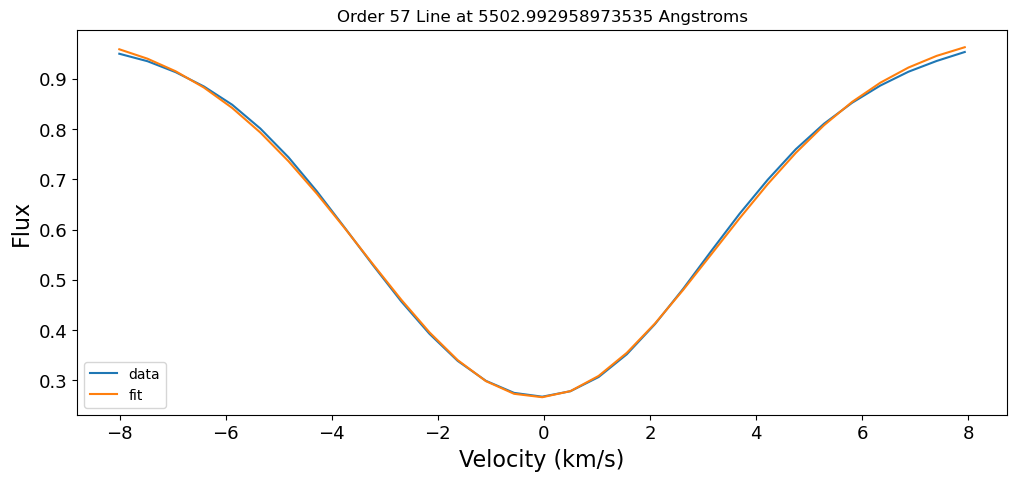

[[Model]]
    Model(gaussian_w_slope)
[[Fit Statistics]]
    # fitting method   = leastsq
    # function evals   = 25
    # data points      = 23
    # variables        = 5
    chi-square         = 5.4074e-04
    reduced chi-square = 3.0041e-05
    Akaike info crit   = -235.135544
    Bayesian info crit = -229.458073
    R-squared          = 0.99958927
[[Variables]]
    amp:   -6.03839697 +/- 0.10812000 (1.79%) (init = -16.89858)
    cen:   -0.10376628 +/- 0.01435533 (13.83%) (init = 0)
    wid:    3.30364451 +/- 0.02804539 (0.85%) (init = 3.304161)
    bas:    0.99984820 +/- 0.00736165 (0.74%) (init = 0)
    slope: -2.5057e-06 +/- 6.1564e-04 (24569.76%) (init = 0)
[[Correlations]] (unreported correlations are < 0.100)
    C(amp, bas)   = -0.9849
    C(amp, wid)   = -0.9690
    C(wid, bas)   = +0.9151
    C(cen, slope) = +0.8742


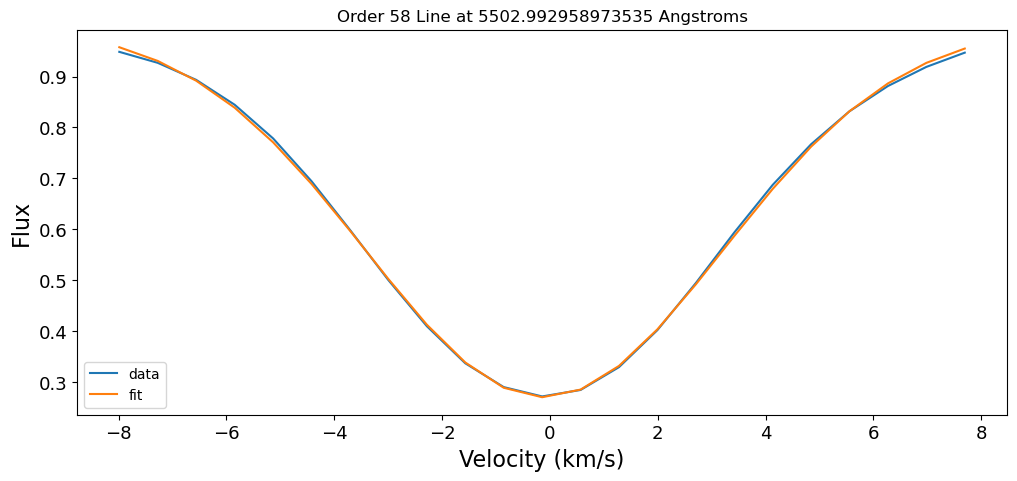

['lambda', 'depth', 'line_id']
1 5503.604195144471 0.13202846001390528
1 5503.604195144471 4981
[[Model]]
    Model(gaussian_w_slope)
[[Fit Statistics]]
    # fitting method   = leastsq
    # function evals   = 37
    # data points      = 31
    # variables        = 5
    chi-square         = 1.0152e-05
    reduced chi-square = 3.9046e-07
    Akaike info crit   = -452.886548
    Bayesian info crit = -445.716612
    R-squared          = 0.99916235
[[Variables]]
    amp:   -0.82596332 +/- 0.00860398 (1.04%) (init = -6.267585)
    cen:    0.14958155 +/- 0.01478873 (9.89%) (init = 0)
    wid:    2.44712010 +/- 0.01929520 (0.79%) (init = 2.447704)
    bas:    0.99998613 +/- 6.1000e-04 (0.06%) (init = 0)
    slope: -1.6107e-07 +/- 7.1236e-05 (44227.48%) (init = 0)
[[Correlations]] (unreported correlations are < 0.100)
    C(amp, bas)   = -0.9016
    C(amp, wid)   = -0.8636
    C(wid, bas)   = +0.7402
    C(cen, slope) = +0.5397


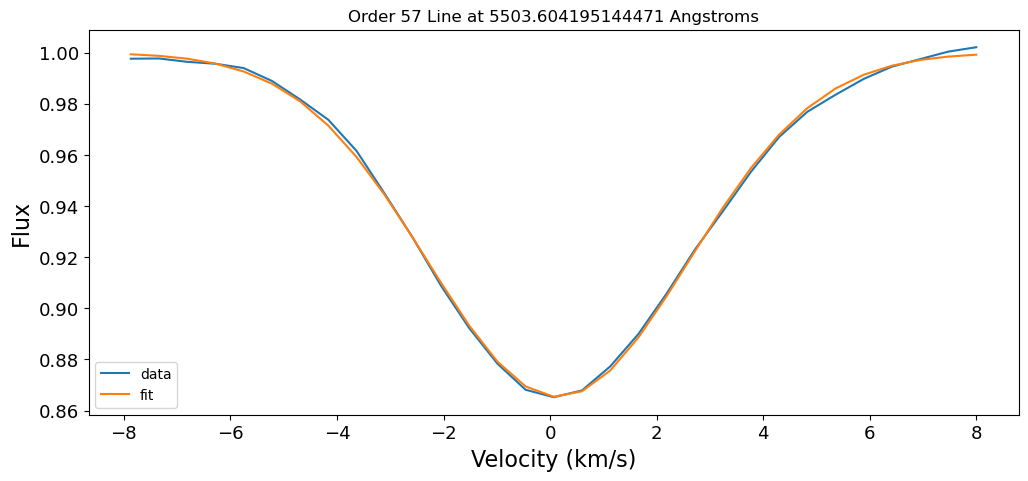

[[Model]]
    Model(gaussian_w_slope)
[[Fit Statistics]]
    # fitting method   = leastsq
    # function evals   = 37
    # data points      = 23
    # variables        = 5
    chi-square         = 5.9637e-06
    reduced chi-square = 3.3132e-07
    Akaike info crit   = -338.802168
    Bayesian info crit = -333.124697
    R-squared          = 0.99932350
[[Variables]]
    amp:   -0.83988812 +/- 0.00967284 (1.15%) (init = -4.637498)
    cen:    0.15401978 +/- 0.01629666 (10.58%) (init = 0)
    wid:    2.50439723 +/- 0.02149950 (0.86%) (init = 2.504934)
    bas:    0.99998702 +/- 6.7723e-04 (0.07%) (init = 0)
    slope: -1.4363e-07 +/- 7.7293e-05 (53813.58%) (init = 0)
[[Correlations]] (unreported correlations are < 0.100)
    C(amp, bas)   = -0.9100
    C(amp, wid)   = -0.8710
    C(wid, bas)   = +0.7562
    C(cen, slope) = +0.5592


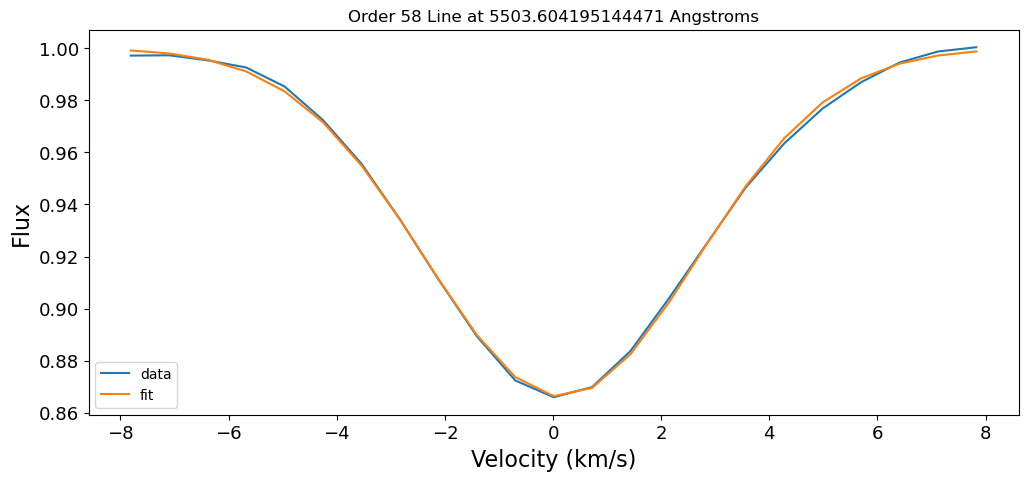

['lambda', 'depth', 'line_id']
2 5505.417489914597 0.11278732409880692
2 5505.417489914597 4983
[[Model]]
    Model(gaussian_w_slope)
[[Fit Statistics]]
    # fitting method   = leastsq
    # function evals   = 31
    # data points      = 31
    # variables        = 5
    chi-square         = 5.3205e-05
    reduced chi-square = 2.0463e-06
    Akaike info crit   = -401.535792
    Bayesian info crit = -394.365856
    R-squared          = 0.99304306
[[Variables]]
    amp:   -0.57271279 +/- 0.01486304 (2.60%) (init = -5.415358)
    cen:   -0.03041188 +/- 0.03617911 (118.96%) (init = 0)
    wid:    2.07696114 +/- 0.04440589 (2.14%) (init = 2.077368)
    bas:    0.99999316 +/- 0.00115785 (0.12%) (init = 0)
    slope: -1.3042e-06 +/- 1.5526e-04 (11904.35%) (init = 0)
[[Correlations]] (unreported correlations are < 0.100)
    C(amp, bas)   = -0.8465
    C(amp, wid)   = -0.8160
    C(wid, bas)   = +0.6506
    C(cen, slope) = +0.4347


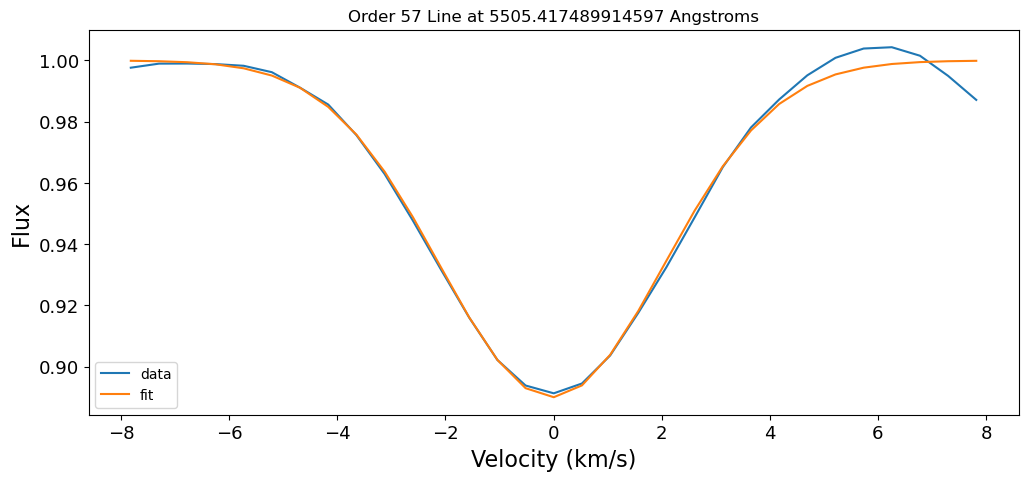

[[Model]]
    Model(gaussian_w_slope)
[[Fit Statistics]]
    # fitting method   = leastsq
    # function evals   = 37
    # data points      = 24
    # variables        = 5
    chi-square         = 7.3814e-05
    reduced chi-square = 3.8850e-06
    Akaike info crit   = -294.608311
    Bayesian info crit = -288.718042
    R-squared          = 0.98710152
[[Variables]]
    amp:   -0.54929952 +/- 0.02204816 (4.01%) (init = -4.184551)
    cen:   -0.04742181 +/- 0.05759053 (121.44%) (init = 0)
    wid:    2.04641020 +/- 0.06953757 (3.40%) (init = 2.047078)
    bas:    0.99999015 +/- 0.00169653 (0.17%) (init = 0)
    slope: -2.2798e-06 +/- 2.2617e-04 (9920.50%) (init = 0)
[[Correlations]] (unreported correlations are < 0.100)
    C(amp, bas)   = -0.8241
    C(amp, wid)   = -0.8000
    C(wid, bas)   = +0.6175
    C(cen, slope) = +0.3974


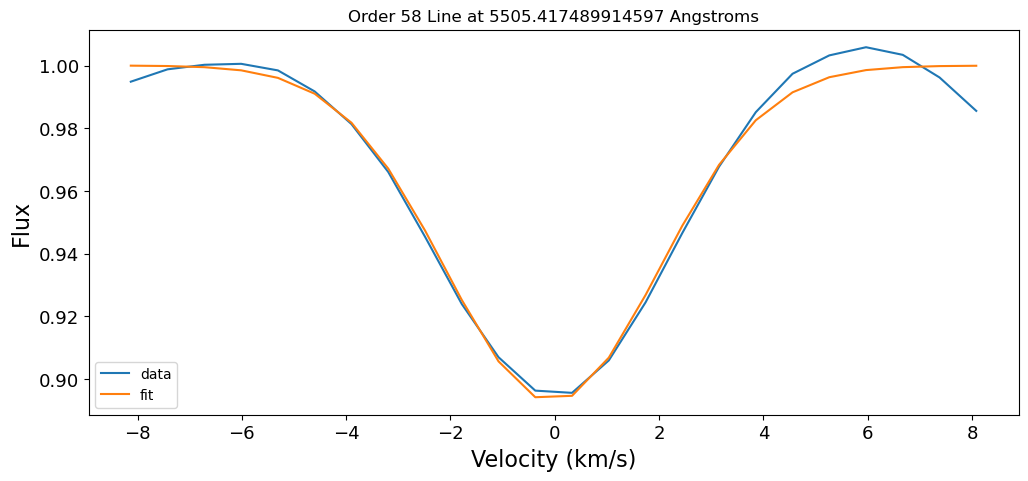

['lambda', 'depth', 'line_id']
3 5508.308449018959 0.7779512398782269
3 5508.308449018959 4985
[[Model]]
    Model(gaussian_w_slope)
[[Fit Statistics]]
    # fitting method   = leastsq
    # function evals   = 31
    # data points      = 32
    # variables        = 5
    chi-square         = 0.00218155
    reduced chi-square = 8.0798e-05
    Akaike info crit   = -296.990525
    Bayesian info crit = -289.661846
    R-squared          = 0.99856557
[[Variables]]
    amp:   -6.72720456 +/- 0.18030423 (2.68%) (init = -24.42927)
    cen:   -0.12301893 +/- 0.02089970 (16.99%) (init = 0)
    wid:    3.51680222 +/- 0.04258776 (1.21%) (init = 3.515812)
    bas:    1.00024887 +/- 0.01179786 (1.18%) (init = 0)
    slope:  1.1118e-06 +/- 8.9779e-04 (80751.84%) (init = 0)
[[Correlations]] (unreported correlations are < 0.100)
    C(amp, bas)   = -0.9891
    C(amp, wid)   = -0.9755
    C(wid, bas)   = +0.9343
    C(cen, slope) = +0.9078


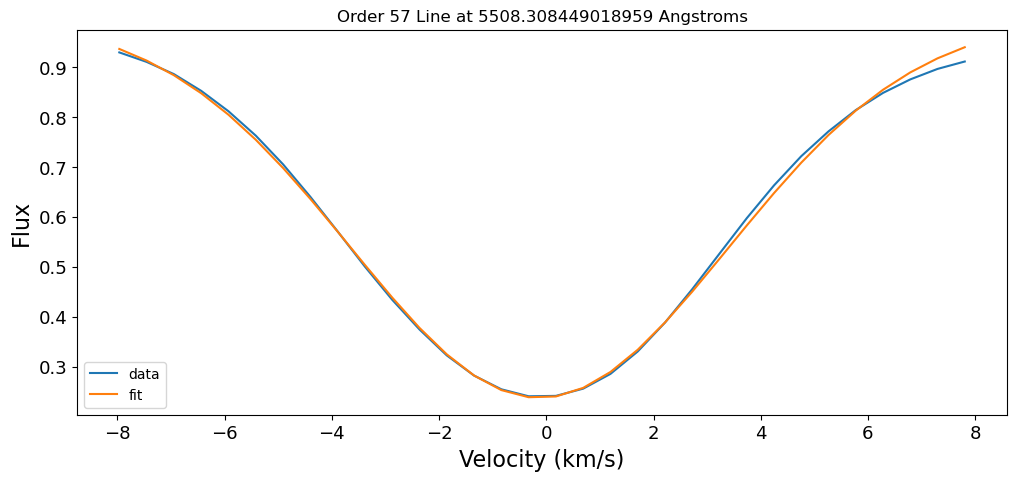

[[Model]]
    Model(gaussian_w_slope)
[[Fit Statistics]]
    # fitting method   = leastsq
    # function evals   = 31
    # data points      = 24
    # variables        = 5
    chi-square         = 0.00192990
    reduced chi-square = 1.0157e-04
    Akaike info crit   = -216.280191
    Bayesian info crit = -210.389922
    R-squared          = 0.99835594
[[Variables]]
    amp:   -6.66313537 +/- 0.22056670 (3.31%) (init = -18.52272)
    cen:   -0.11975812 +/- 0.02640216 (22.05%) (init = 0)
    wid:    3.50254065 +/- 0.05304180 (1.51%) (init = 3.501742)
    bas:    1.00019685 +/- 0.01440834 (1.44%) (init = 0)
    slope:  3.2407e-07 +/- 0.00112070 (345814.48%) (init = 0)
[[Correlations]] (unreported correlations are < 0.100)
    C(amp, bas)   = -0.9877
    C(amp, wid)   = -0.9732
    C(wid, bas)   = +0.9275
    C(cen, slope) = +0.8995


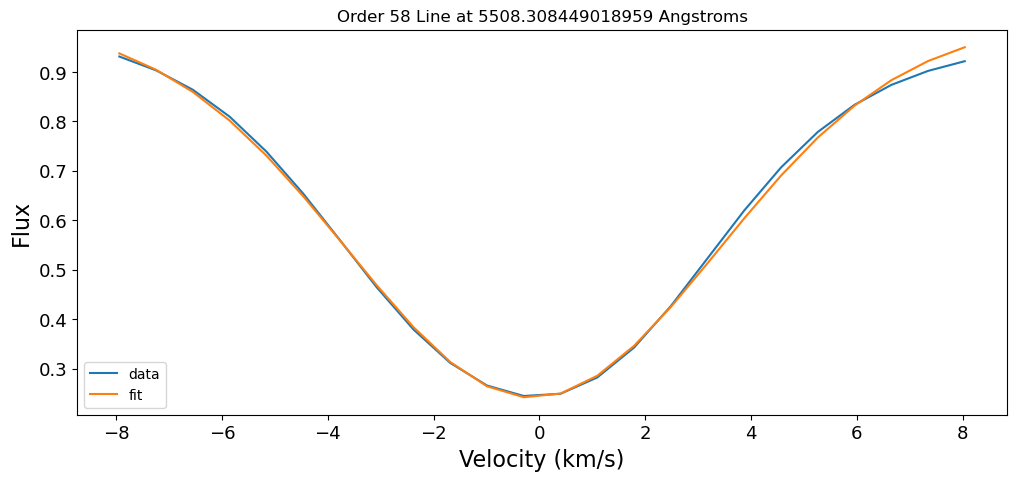

['lambda', 'depth', 'line_id']
4 5509.9274944808585 0.12946804863130632
4 5509.9274944808585 4986
[[Model]]
    Model(gaussian_w_slope)
[[Fit Statistics]]
    # fitting method   = leastsq
    # function evals   = 31
    # data points      = 33
    # variables        = 5
    chi-square         = 4.1633e-05
    reduced chi-square = 1.4869e-06
    Akaike info crit   = -438.243243
    Bayesian info crit = -430.760705
    R-squared          = 0.99608488
[[Variables]]
    amp:   -0.72771127 +/- 0.01491974 (2.05%) (init = -6.564485)
    cen:    0.07310253 +/- 0.02958390 (40.47%) (init = 0)
    wid:    2.35853974 +/- 0.03775061 (1.60%) (init = 2.358848)
    bas:    0.99999312 +/- 0.00107454 (0.11%) (init = 0)
    slope: -1.8791e-06 +/- 1.2966e-04 (6900.19%) (init = 0)
[[Correlations]] (unreported correlations are < 0.100)
    C(amp, bas)   = -0.8842
    C(amp, wid)   = -0.8468
    C(wid, bas)   = +0.7100
    C(cen, slope) = +0.5038


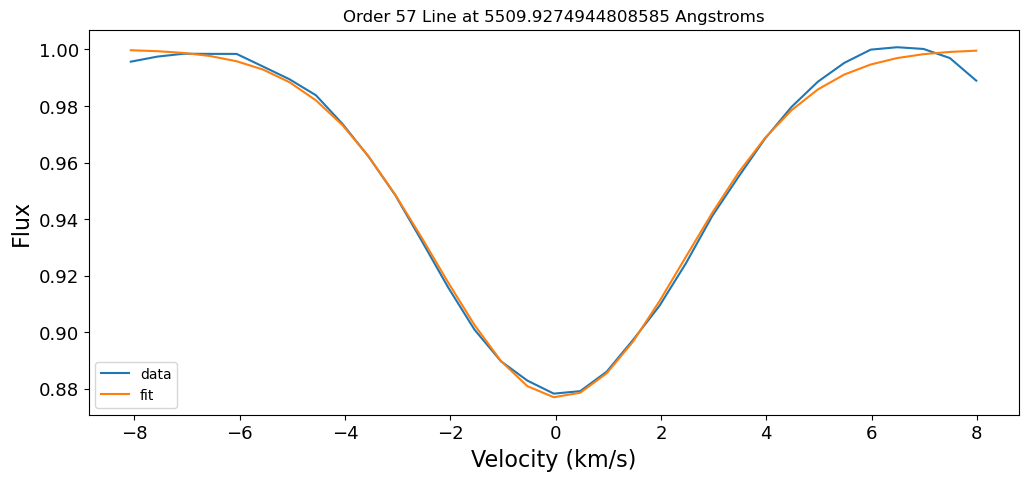

[[Model]]
    Model(gaussian_w_slope)
[[Fit Statistics]]
    # fitting method   = leastsq
    # function evals   = 31
    # data points      = 24
    # variables        = 5
    chi-square         = 1.6095e-05
    reduced chi-square = 8.4708e-07
    Akaike info crit   = -331.162070
    Bayesian info crit = -325.271801
    R-squared          = 0.99780235
[[Variables]]
    amp:   -0.70883805 +/- 0.01301878 (1.84%) (init = -4.761332)
    cen:    0.08403504 +/- 0.02649202 (31.52%) (init = 0)
    wid:    2.34549317 +/- 0.03370676 (1.44%) (init = 2.345422)
    bas:    1.00000045 +/- 9.3966e-04 (0.09%) (init = 0)
    slope: -1.1979e-06 +/- 1.1395e-04 (9512.48%) (init = 0)
[[Correlations]] (unreported correlations are < 0.100)
    C(amp, bas)   = -0.8828
    C(amp, wid)   = -0.8457
    C(wid, bas)   = +0.7084
    C(cen, slope) = +0.5011


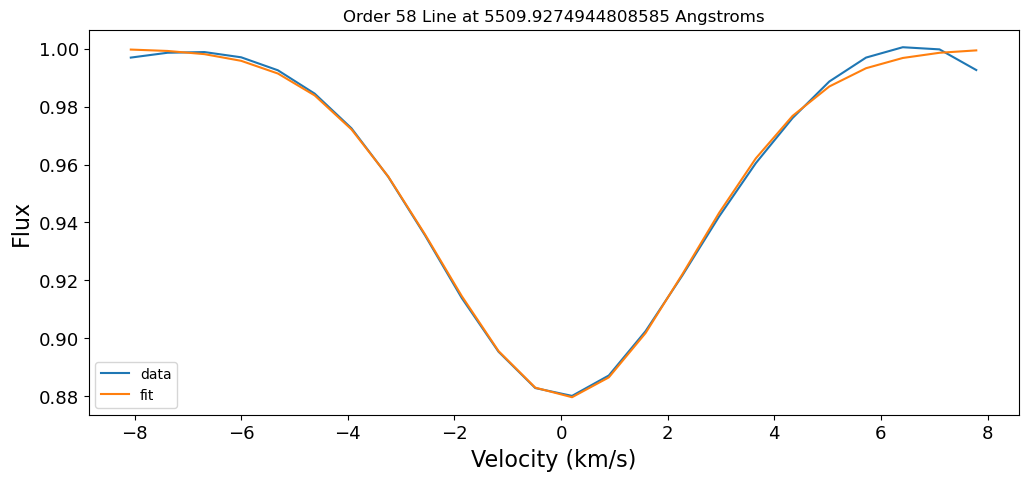

['lambda', 'depth', 'line_id']
5 5510.141195758091 0.11863937854976107
5 5510.141195758091 4987
[[Model]]
    Model(gaussian_w_slope)
[[Fit Statistics]]
    # fitting method   = leastsq
    # function evals   = 49
    # data points      = 33
    # variables        = 5
    chi-square         = 2.9392e-04
    reduced chi-square = 1.0497e-05
    Akaike info crit   = -373.747427
    Bayesian info crit = -366.264889
    R-squared          = 0.96384290
[[Variables]]
    amp:   -0.58757221 +/- 0.03807475 (6.48%) (init = -6.001455)
    cen:    0.52520481 +/- 0.09185836 (17.49%) (init = 0)
    wid:    2.27551636 +/- 0.11616819 (5.11%) (init = 2.280709)
    bas:    0.99991679 +/- 0.00276518 (0.28%) (init = 0)
    slope:  5.2053e-07 +/- 3.4722e-04 (66705.46%) (init = 0)
[[Correlations]] (unreported correlations are < 0.100)
    C(amp, bas)   = -0.8771
    C(amp, wid)   = -0.8377
    C(wid, bas)   = +0.7010
    C(cen, slope) = +0.4907
    C(amp, slope) = -0.3003
    C(bas, slope) = +0.2874
    C(w

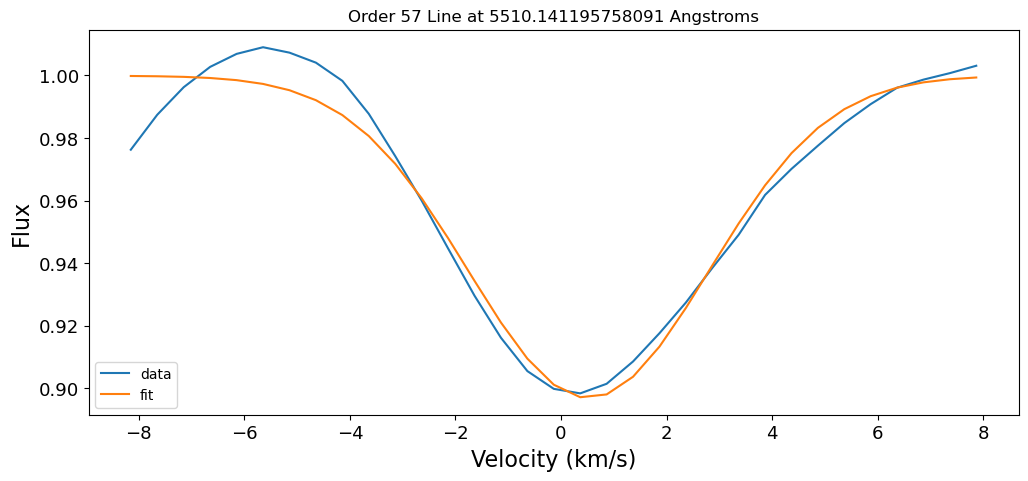

[[Model]]
    Model(gaussian_w_slope)
[[Fit Statistics]]
    # fitting method   = leastsq
    # function evals   = 43
    # data points      = 24
    # variables        = 5
    chi-square         = 1.8470e-04
    reduced chi-square = 9.7211e-06
    Akaike info crit   = -272.595834
    Bayesian info crit = -266.705565
    R-squared          = 0.96790751
[[Variables]]
    amp:   -0.58639140 +/- 0.04338045 (7.40%) (init = -4.350376)
    cen:    0.55416284 +/- 0.10558909 (19.05%) (init = 0)
    wid:    2.30145033 +/- 0.13370669 (5.81%) (init = 2.306878)
    bas:    0.99991270 +/- 0.00312330 (0.31%) (init = 0)
    slope: -2.3060e-07 +/- 3.8928e-04 (168814.92%) (init = 0)
[[Correlations]] (unreported correlations are < 0.100)
    C(amp, bas)   = -0.8793
    C(amp, wid)   = -0.8398
    C(wid, bas)   = +0.7055
    C(cen, slope) = +0.4970
    C(amp, slope) = -0.2843
    C(bas, slope) = +0.2650
    C(wid, slope) = +0.2195
    C(amp, cen)   = -0.1524
    C(cen, bas)   = +0.1321
    C(cen, wid)   

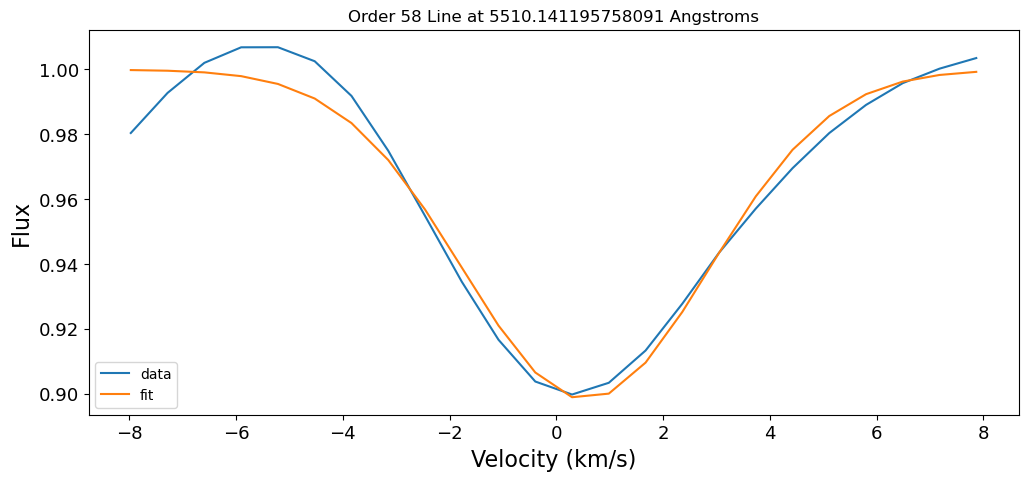

['lambda', 'depth', 'line_id']
6 5513.781385991351 0.2490474822986517
6 5513.781385991351 4990
[[Model]]
    Model(gaussian_w_slope)
[[Fit Statistics]]
    # fitting method   = leastsq
    # function evals   = 37
    # data points      = 34
    # variables        = 5
    chi-square         = 5.1531e-04
    reduced chi-square = 1.7769e-05
    Akaike info crit   = -367.301763
    Bayesian info crit = -359.669960
    R-squared          = 0.99357146
[[Variables]]
    amp:   -1.33810948 +/- 0.03318366 (2.48%) (init = -11.53804)
    cen:   -0.21387813 +/- 0.03076256 (14.38%) (init = 0)
    wid:    2.06571738 +/- 0.03985181 (1.93%) (init = 2.071937)
    bas:    0.99973588 +/- 0.00272606 (0.27%) (init = 0)
    slope: -1.5128e-05 +/- 3.6819e-04 (2433.73%) (init = 0)
[[Correlations]] (unreported correlations are < 0.100)
    C(amp, bas)   = -0.8687
    C(amp, wid)   = -0.8512
    C(wid, bas)   = +0.6540
    C(cen, slope) = +0.4470
    C(bas, slope) = -0.3346
    C(amp, slope) = +0.2976
    C(wid

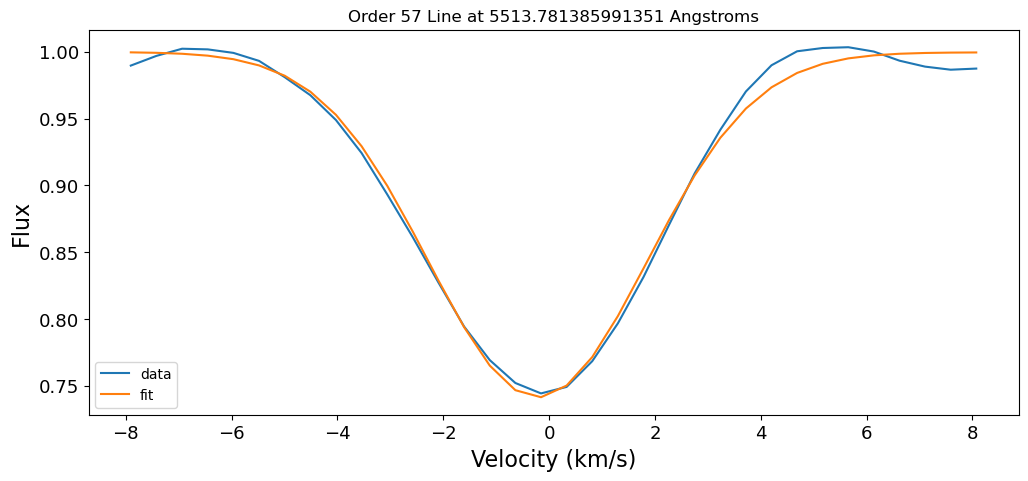

[[Model]]
    Model(gaussian_w_slope)
[[Fit Statistics]]
    # fitting method   = leastsq
    # function evals   = 31
    # data points      = 24
    # variables        = 5
    chi-square         = 3.3487e-04
    reduced chi-square = 1.7625e-05
    Akaike info crit   = -258.315649
    Bayesian info crit = -252.425380
    R-squared          = 0.99400550
[[Variables]]
    amp:   -1.32779752 +/- 0.03915557 (2.95%) (init = -8.126563)
    cen:   -0.20290295 +/- 0.03660061 (18.04%) (init = 0)
    wid:    2.06984980 +/- 0.04742459 (2.29%) (init = 2.075527)
    bas:    0.99974854 +/- 0.00321849 (0.32%) (init = 0)
    slope: -1.5557e-05 +/- 4.3744e-04 (2811.92%) (init = 0)
[[Correlations]] (unreported correlations are < 0.100)
    C(amp, bas)   = -0.8705
    C(amp, wid)   = -0.8525
    C(wid, bas)   = +0.6585
    C(cen, slope) = +0.4536
    C(bas, slope) = -0.2630
    C(amp, slope) = +0.2352
    C(wid, slope) = -0.1561
    C(amp, cen)   = +0.1467
    C(cen, bas)   = -0.1209
    C(cen, wid)   = 

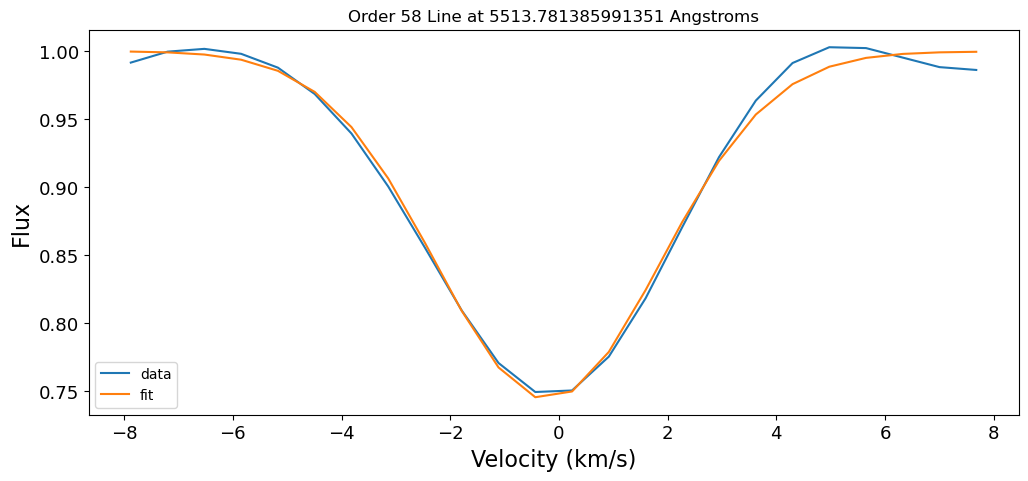

['lambda', 'depth', 'line_id']
7 5514.050473544801 0.34738223986482764
7 5514.050473544801 4991
[[Model]]
    Model(gaussian_w_slope)
[[Fit Statistics]]
    # fitting method   = leastsq
    # function evals   = 31
    # data points      = 34
    # variables        = 5
    chi-square         = 4.2963e-04
    reduced chi-square = 1.4815e-05
    Akaike info crit   = -373.483900
    Bayesian info crit = -365.852097
    R-squared          = 0.99677580
[[Variables]]
    amp:   -1.86136932 +/- 0.03349093 (1.80%) (init = -15.54116)
    cen:    0.05485628 +/- 0.02143466 (39.07%) (init = 0)
    wid:    2.24847370 +/- 0.02921999 (1.30%) (init = 2.245807)
    bas:    1.00009517 +/- 0.00267726 (0.27%) (init = 0)
    slope: -1.5719e-05 +/- 3.4152e-04 (2172.70%) (init = 0)
[[Correlations]] (unreported correlations are < 0.100)
    C(amp, bas)   = -0.9021
    C(amp, wid)   = -0.8831
    C(wid, bas)   = +0.7072
    C(cen, slope) = +0.5171
    C(bas, slope) = +0.3196
    C(amp, slope) = -0.2676
    C(am

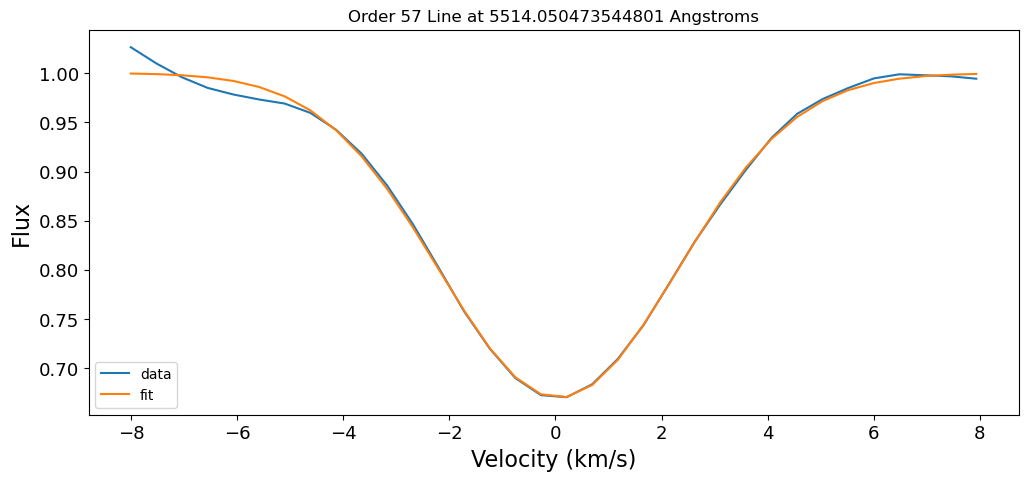

[[Model]]
    Model(gaussian_w_slope)
[[Fit Statistics]]
    # fitting method   = leastsq
    # function evals   = 31
    # data points      = 24
    # variables        = 5
    chi-square         = 1.4948e-04
    reduced chi-square = 7.8676e-06
    Akaike info crit   = -277.673054
    Bayesian info crit = -271.782785
    R-squared          = 0.99842943
[[Variables]]
    amp:   -1.84397436 +/- 0.02864913 (1.55%) (init = -10.93127)
    cen:    0.07086237 +/- 0.01838338 (25.94%) (init = 0)
    wid:    2.23683911 +/- 0.02509894 (1.12%) (init = 2.235426)
    bas:    1.00002741 +/- 0.00230010 (0.23%) (init = 0)
    slope: -9.9351e-06 +/- 2.9580e-04 (2977.32%) (init = 0)
[[Correlations]] (unreported correlations are < 0.100)
    C(amp, bas)   = -0.9031
    C(amp, wid)   = -0.8840
    C(wid, bas)   = +0.7102
    C(cen, slope) = +0.5199
    C(bas, slope) = +0.2578
    C(amp, slope) = -0.2141
    C(amp, cen)   = -0.1517
    C(wid, slope) = +0.1350
    C(cen, bas)   = +0.1332
    C(cen, wid)   = 

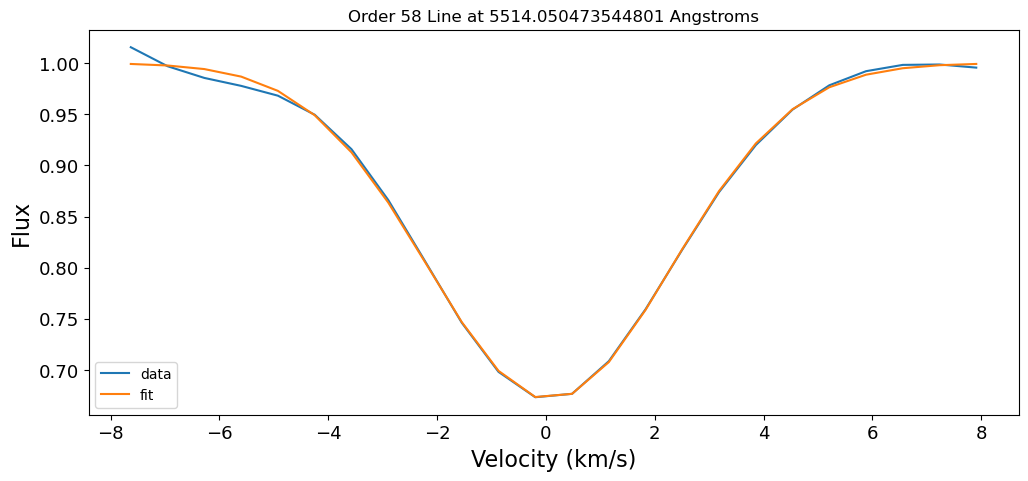

['lambda', 'depth', 'line_id']
8 5514.5070741219515 0.5205270631244967
8 5514.5070741219515 4992
[[Model]]
    Model(gaussian_w_slope)
[[Fit Statistics]]
    # fitting method   = leastsq
    # function evals   = 31
    # data points      = 34
    # variables        = 5
    chi-square         = 1.1863e-04
    reduced chi-square = 4.0906e-06
    Akaike info crit   = -417.239926
    Bayesian info crit = -409.608123
    R-squared          = 0.99975812
[[Variables]]
    amp:   -4.19650418 +/- 0.03148977 (0.75%) (init = -20.69058)
    cen:   -0.09714641 +/- 0.00720737 (7.42%) (init = 0)
    wid:    3.01296281 +/- 0.01243332 (0.41%) (init = 3.01227)
    bas:    1.00009891 +/- 0.00217662 (0.22%) (init = 0)
    slope: -1.8057e-06 +/- 2.0340e-04 (11264.18%) (init = 0)
[[Correlations]] (unreported correlations are < 0.100)
    C(amp, bas)   = -0.9726
    C(amp, wid)   = -0.9532
    C(wid, bas)   = +0.8733
    C(cen, slope) = +0.7674
    C(amp, slope) = +0.1101
    C(bas, slope) = -0.1035


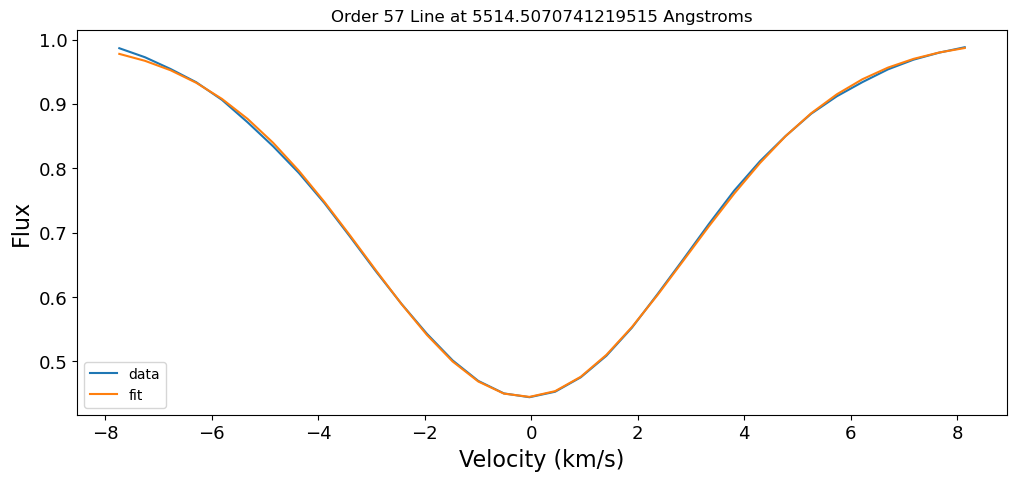

[[Model]]
    Model(gaussian_w_slope)
[[Fit Statistics]]
    # fitting method   = leastsq
    # function evals   = 31
    # data points      = 25
    # variables        = 5
    chi-square         = 1.3910e-04
    reduced chi-square = 6.9549e-06
    Akaike info crit   = -292.480216
    Bayesian info crit = -286.385837
    R-squared          = 0.99965636
[[Variables]]
    amp:   -4.16021240 +/- 0.04443678 (1.07%) (init = -15.30972)
    cen:   -0.09548322 +/- 0.01058668 (11.09%) (init = 0)
    wid:    2.99000945 +/- 0.01792550 (0.60%) (init = 2.989284)
    bas:    1.00010072 +/- 0.00306947 (0.31%) (init = 0)
    slope: -1.2485e-06 +/- 2.9234e-04 (23415.37%) (init = 0)
[[Correlations]] (unreported correlations are < 0.100)
    C(amp, bas)   = -0.9681
    C(amp, wid)   = -0.9484
    C(wid, bas)   = +0.8576
    C(cen, slope) = +0.7454


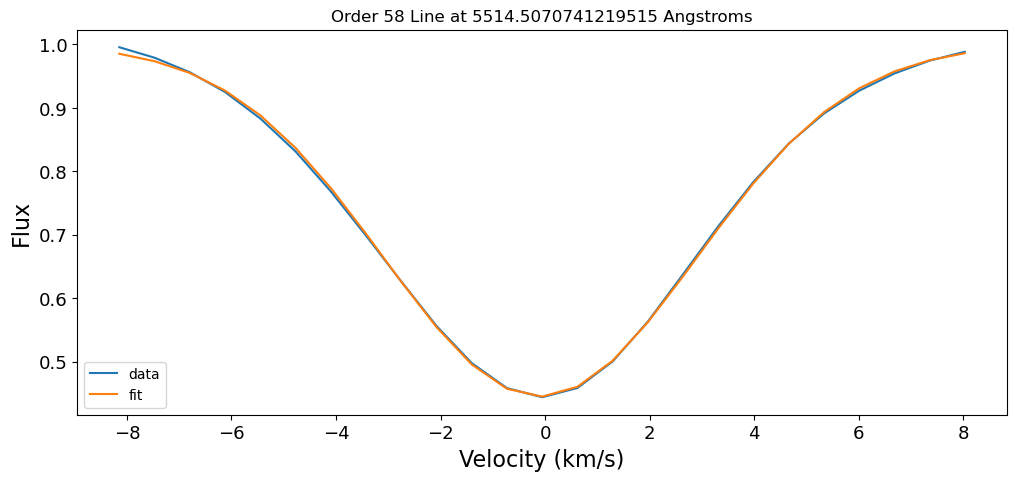

['lambda', 'depth', 'line_id']
9 5515.869416212336 0.300229597471207
9 5515.869416212336 4993
[[Model]]
    Model(gaussian_w_slope)
[[Fit Statistics]]
    # fitting method   = leastsq
    # function evals   = 55
    # data points      = 35
    # variables        = 5
    chi-square         = 0.00845474
    reduced chi-square = 2.8182e-04
    Akaike info crit   = -281.493173
    Bayesian info crit = -273.716433
    R-squared          = 0.91603743
[[Variables]]
    amp:   -1.25403229 +/- 0.11280660 (9.00%) (init = -14.47929)
    cen:   -0.22064361 +/- 0.10809710 (48.99%) (init = 0)
    wid:    1.88633727 +/- 0.13755349 (7.29%) (init = 1.897657)
    bas:    0.99966067 +/- 0.00985722 (0.99%) (init = 0)
    slope: -1.2024e-04 +/- 0.00138366 (1150.77%) (init = 0)
[[Correlations]] (unreported correlations are < 0.100)
    C(amp, bas)   = -0.8391
    C(amp, wid)   = -0.8333
    C(wid, bas)   = +0.6012
    C(cen, slope) = +0.3855
    C(bas, slope) = -0.3241
    C(amp, slope) = +0.2867
    C(wid,

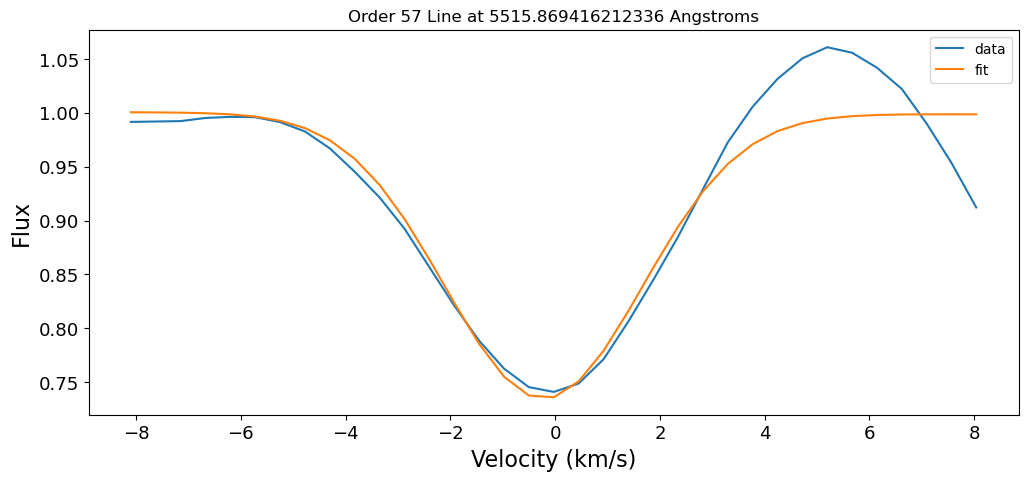

[[Model]]
    Model(gaussian_w_slope)
[[Fit Statistics]]
    # fitting method   = leastsq
    # function evals   = 55
    # data points      = 24
    # variables        = 5
    chi-square         = 0.00481632
    reduced chi-square = 2.5349e-04
    Akaike info crit   = -194.331165
    Bayesian info crit = -188.440895
    R-squared          = 0.93103614
[[Variables]]
    amp:   -1.28565226 +/- 0.13318161 (10.36%) (init = -9.873409)
    cen:   -0.20386023 +/- 0.12159077 (59.64%) (init = 0)
    wid:    1.90521047 +/- 0.15660075 (8.22%) (init = 1.916048)
    bas:    0.99962144 +/- 0.01172981 (1.17%) (init = 0)
    slope: -9.4482e-05 +/- 0.00166408 (1761.26%) (init = 0)
[[Correlations]] (unreported correlations are < 0.100)
    C(amp, bas)   = -0.8540
    C(amp, wid)   = -0.8419
    C(wid, bas)   = +0.6243
    C(cen, slope) = +0.4128
    C(bas, slope) = -0.3430
    C(amp, slope) = +0.3061
    C(wid, slope) = -0.2103
    C(amp, cen)   = +0.1757
    C(cen, bas)   = -0.1481
    C(cen, wid)   =

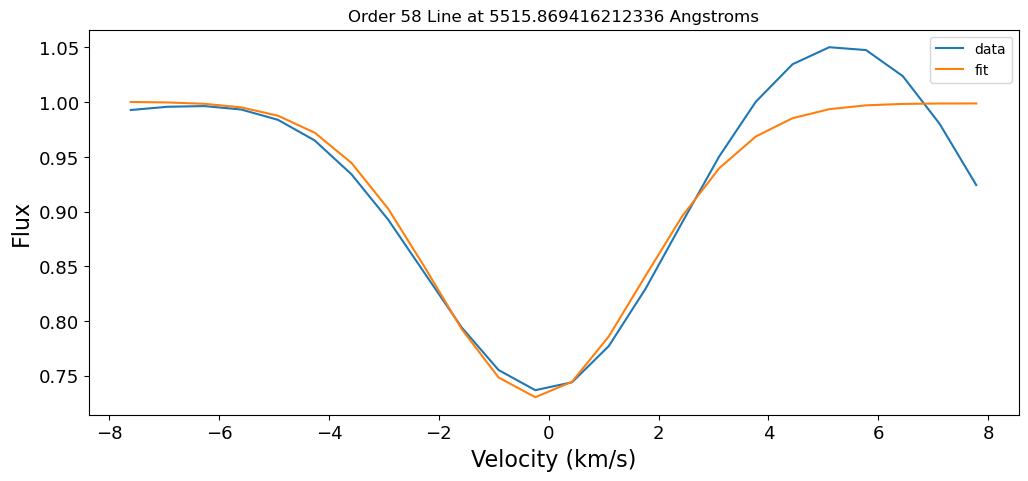

['lambda', 'depth', 'line_id']
10 5516.05980972038 0.3540605364755198
10 5516.05980972038 4994
[[Model]]
    Model(gaussian_w_slope)
[[Fit Statistics]]
    # fitting method   = leastsq
    # function evals   = 49
    # data points      = 35
    # variables        = 5
    chi-square         = 0.00513681
    reduced chi-square = 1.7123e-04
    Akaike info crit   = -298.933471
    Bayesian info crit = -291.156731
    R-squared          = 0.96462423
[[Variables]]
    amp:   -1.72194641 +/- 0.10019107 (5.82%) (init = -16.76025)
    cen:    0.19783256 +/- 0.06829402 (34.52%) (init = 0)
    wid:    2.08243766 +/- 0.09153556 (4.40%) (init = 2.093122)
    bas:    0.99941217 +/- 0.00840845 (0.84%) (init = 0)
    slope:  5.9779e-05 +/- 0.00112585 (1883.34%) (init = 0)
[[Correlations]] (unreported correlations are < 0.100)
    C(amp, bas)   = -0.8779
    C(amp, wid)   = -0.8647
    C(wid, bas)   = +0.6561
    C(cen, slope) = +0.4577
    C(bas, slope) = +0.2913
    C(amp, slope) = -0.2668
    C(wid

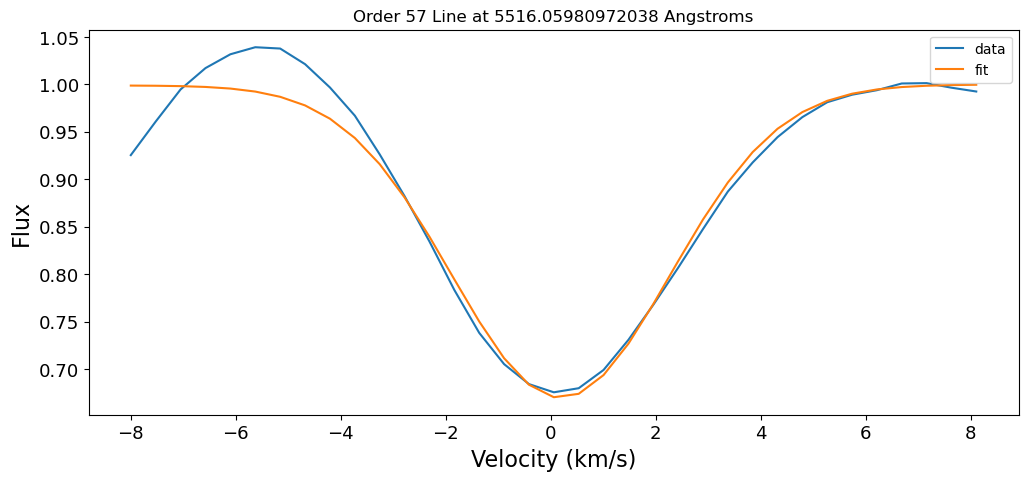

[[Model]]
    Model(gaussian_w_slope)
[[Fit Statistics]]
    # fitting method   = leastsq
    # function evals   = 43
    # data points      = 25
    # variables        = 5
    chi-square         = 0.00356929
    reduced chi-square = 1.7846e-04
    Akaike info crit   = -211.356629
    Bayesian info crit = -205.262250
    R-squared          = 0.96507946
[[Variables]]
    amp:   -1.71558024 +/- 0.11913906 (6.94%) (init = -11.95517)
    cen:    0.18766295 +/- 0.08212461 (43.76%) (init = 0)
    wid:    2.07784324 +/- 0.10960936 (5.28%) (init = 2.088691)
    bas:    0.99939967 +/- 0.00998359 (1.00%) (init = 0)
    slope:  5.3568e-05 +/- 0.00133615 (2494.31%) (init = 0)
[[Correlations]] (unreported correlations are < 0.100)
    C(amp, bas)   = -0.8746
    C(amp, wid)   = -0.8632
    C(wid, bas)   = +0.6508
    C(cen, slope) = +0.4512
    C(bas, slope) = +0.2681
    C(amp, slope) = -0.2455
    C(wid, slope) = +0.1683
    C(amp, cen)   = -0.1529
    C(cen, bas)   = +0.1272
    C(cen, wid)   = 

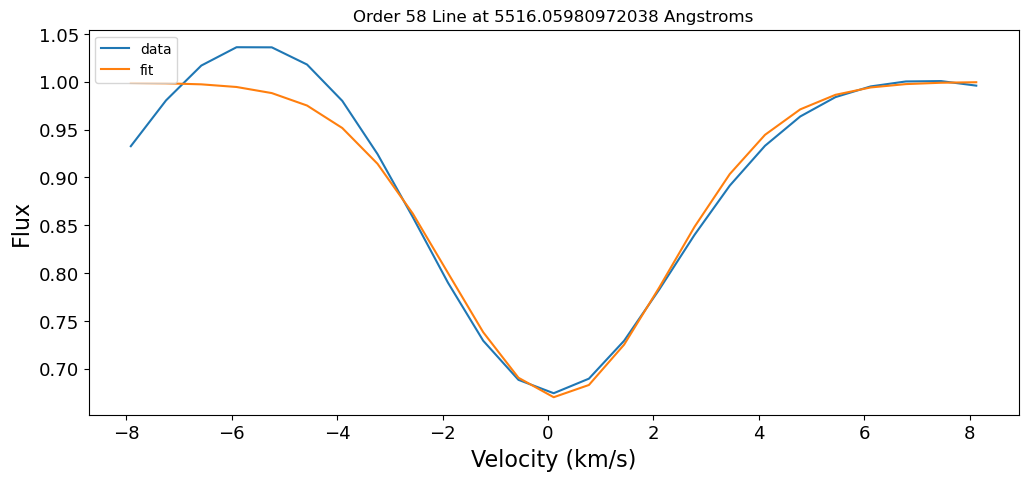

['lambda', 'depth', 'line_id']
11 5518.592282417049 0.1394168130352646
11 5518.592282417049 4996
[[Model]]
    Model(gaussian_w_slope)
[[Fit Statistics]]
    # fitting method   = leastsq
    # function evals   = 31
    # data points      = 25
    # variables        = 5
    chi-square         = 1.3626e-05
    reduced chi-square = 6.8128e-07
    Akaike info crit   = -350.560821
    Bayesian info crit = -344.466442
    R-squared          = 0.99870606
[[Variables]]
    amp:   -0.86111281 +/- 0.01176761 (1.37%) (init = -5.358764)
    cen:    0.08202375 +/- 0.01931594 (23.55%) (init = 0)
    wid:    2.35665903 +/- 0.02484840 (1.05%) (init = 2.357082)
    bas:    0.99998951 +/- 8.5396e-04 (0.09%) (init = 0)
    slope:  6.3935e-08 +/- 1.0331e-04 (161585.28%) (init = 0)
[[Correlations]] (unreported correlations are < 0.100)
    C(amp, bas)   = -0.8891
    C(amp, wid)   = -0.8541
    C(wid, bas)   = +0.7151
    C(cen, slope) = +0.5103


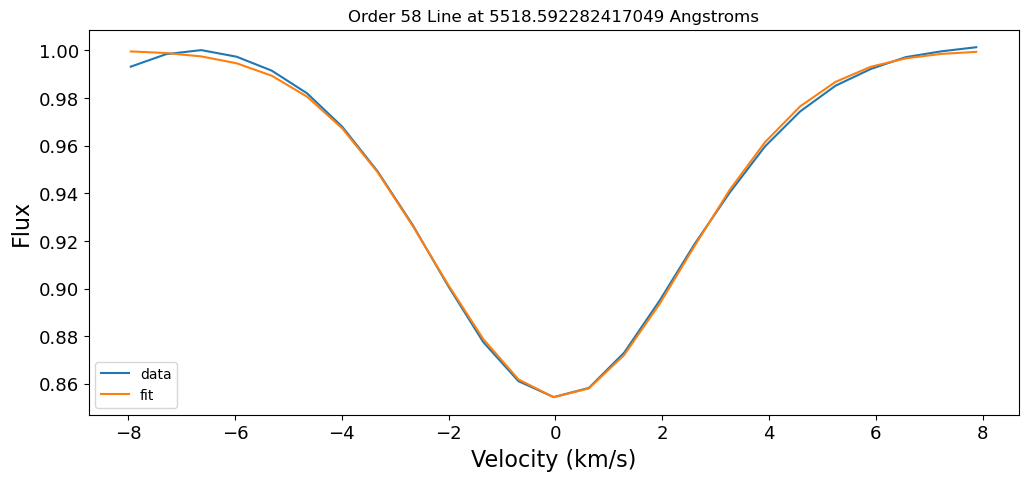

Now fitting for EXPRES...
['lambda', 'depth', 'line_id']
0 5502.992958973535 0.7273424558592381
0 5502.992958973535 4980
[[Model]]
    Model(gaussian_w_slope)
[[Fit Statistics]]
    # fitting method   = leastsq
    # function evals   = 25
    # data points      = 27
    # variables        = 5
    chi-square         = 9.5881e-04
    reduced chi-square = 4.3582e-05
    Akaike info crit   = -266.632772
    Bayesian info crit = -260.153587
    R-squared          = 0.99941435
[[Variables]]
    amp:   -6.08329004 +/- 0.11999912 (1.97%) (init = -19.79517)
    cen:   -0.11202099 +/- 0.01573264 (14.04%) (init = 0)
    wid:    3.30634852 +/- 0.03081376 (0.93%) (init = 3.306969)
    bas:    0.99982015 +/- 0.00817873 (0.82%) (init = 0)
    slope: -2.9227e-06 +/- 6.8451e-04 (23420.06%) (init = 0)
[[Correlations]] (unreported correlations are < 0.100)
    C(amp, bas)   = -0.9850
    C(amp, wid)   = -0.9691
    C(wid, bas)   = +0.9154
    C(cen, slope) = +0.8768


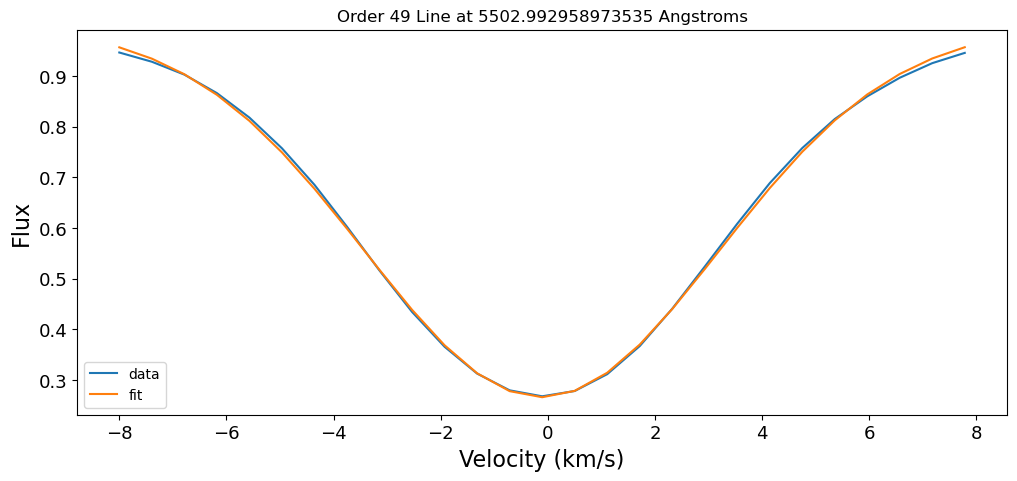

['lambda', 'depth', 'line_id']
1 5503.604195144471 0.13202846001390528
1 5503.604195144471 4981
[[Model]]
    Model(gaussian_w_slope)
[[Fit Statistics]]
    # fitting method   = leastsq
    # function evals   = 37
    # data points      = 27
    # variables        = 5
    chi-square         = 7.6715e-06
    reduced chi-square = 3.4870e-07
    Akaike info crit   = -396.993621
    Bayesian info crit = -390.514437
    R-squared          = 0.99933663
[[Variables]]
    amp:   -0.83828178 +/- 0.00883574 (1.05%) (init = -5.437964)
    cen:    0.13068049 +/- 0.01486240 (11.37%) (init = 0)
    wid:    2.46281932 +/- 0.01950901 (0.79%) (init = 2.463363)
    bas:    0.99998678 +/- 6.2545e-04 (0.06%) (init = 0)
    slope: -1.3299e-07 +/- 7.2600e-05 (54589.44%) (init = 0)
[[Correlations]] (unreported correlations are < 0.100)
    C(amp, bas)   = -0.9056
    C(amp, wid)   = -0.8670
    C(wid, bas)   = +0.7472
    C(cen, slope) = +0.5482
    C(bas, slope) = +0.1156
    C(amp, slope) = -0.1146


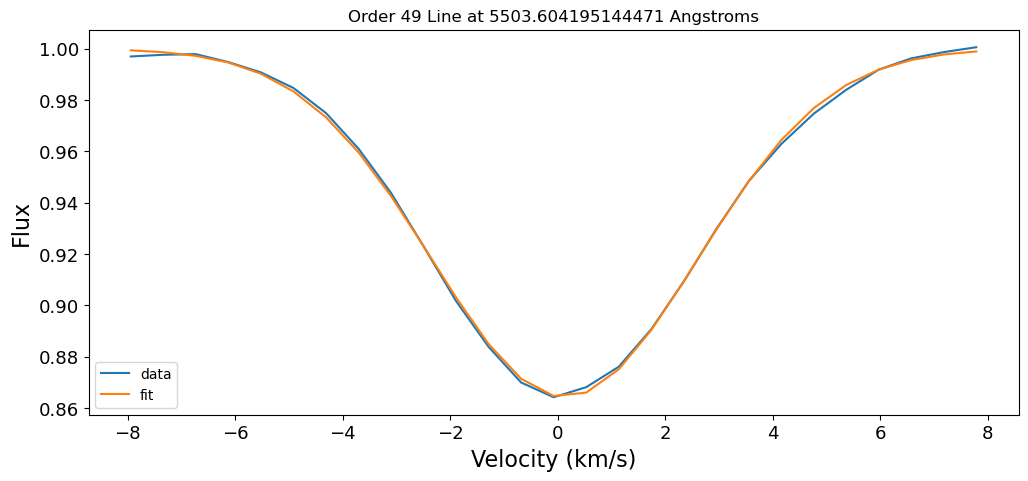

['lambda', 'depth', 'line_id']
2 5505.417489914597 0.11278732409880692
2 5505.417489914597 4983
[[Model]]
    Model(gaussian_w_slope)
[[Fit Statistics]]
    # fitting method   = leastsq
    # function evals   = 31
    # data points      = 27
    # variables        = 5
    chi-square         = 5.0940e-05
    reduced chi-square = 2.3154e-06
    Akaike info crit   = -345.879136
    Bayesian info crit = -339.399952
    R-squared          = 0.99261368
[[Variables]]
    amp:   -0.57734625 +/- 0.01668057 (2.89%) (init = -4.704736)
    cen:   -0.03127187 +/- 0.04023379 (128.66%) (init = 0)
    wid:    2.06600929 +/- 0.04932381 (2.39%) (init = 2.066263)
    bas:    0.99999554 +/- 0.00130336 (0.13%) (init = 0)
    slope: -1.5198e-06 +/- 1.7538e-04 (11539.98%) (init = 0)
[[Correlations]] (unreported correlations are < 0.100)
    C(amp, bas)   = -0.8441
    C(amp, wid)   = -0.8145
    C(wid, bas)   = +0.6465
    C(cen, slope) = +0.4303


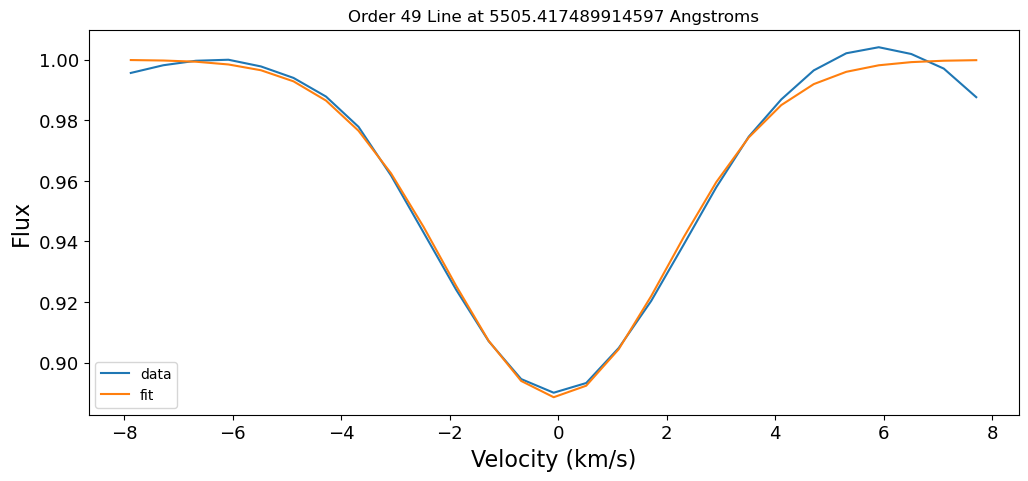

['lambda', 'depth', 'line_id']
3 5508.308449018959 0.7779512398782269
3 5508.308449018959 4985
[[Model]]
    Model(gaussian_w_slope)
[[Fit Statistics]]
    # fitting method   = leastsq
    # function evals   = 31
    # data points      = 28
    # variables        = 5
    chi-square         = 0.00239130
    reduced chi-square = 1.0397e-04
    Akaike info crit   = -252.307406
    Bayesian info crit = -245.646383
    R-squared          = 0.99818671
[[Variables]]
    amp:   -6.76085531 +/- 0.21467836 (3.18%) (init = -21.50727)
    cen:   -0.13168858 +/- 0.02505885 (19.03%) (init = 0)
    wid:    3.52812911 +/- 0.05079438 (1.44%) (init = 3.527114)
    bas:    1.00025161 +/- 0.01399338 (1.40%) (init = 0)
    slope:  2.5705e-06 +/- 0.00107050 (41645.91%) (init = 0)
[[Correlations]] (unreported correlations are < 0.100)
    C(amp, bas)   = -0.9885
    C(amp, wid)   = -0.9745
    C(wid, bas)   = +0.9312
    C(cen, slope) = +0.9054


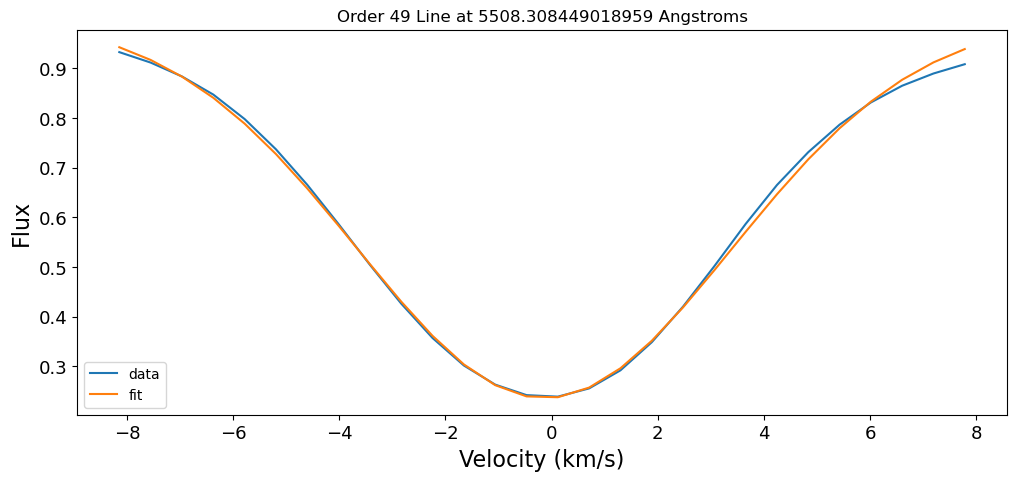

['lambda', 'depth', 'line_id']
4 5509.9274944808585 0.12946804863130632
4 5509.9274944808585 4986
[[Model]]
    Model(gaussian_w_slope)
[[Fit Statistics]]
    # fitting method   = leastsq
    # function evals   = 31
    # data points      = 28
    # variables        = 5
    chi-square         = 1.5772e-05
    reduced chi-square = 6.8576e-07
    Akaike info crit   = -392.904606
    Bayesian info crit = -386.243583
    R-squared          = 0.99822040
[[Variables]]
    amp:   -0.71687932 +/- 0.01074694 (1.50%) (init = -5.565027)
    cen:    0.10589933 +/- 0.02132936 (20.14%) (init = 0)
    wid:    2.31655021 +/- 0.02717109 (1.17%) (init = 2.316569)
    bas:    0.99999872 +/- 7.8533e-04 (0.08%) (init = 0)
    slope: -1.1090e-06 +/- 9.6388e-05 (8691.65%) (init = 0)
[[Correlations]] (unreported correlations are < 0.100)
    C(amp, bas)   = -0.8827
    C(amp, wid)   = -0.8460
    C(wid, bas)   = +0.7077
    C(cen, slope) = +0.5002


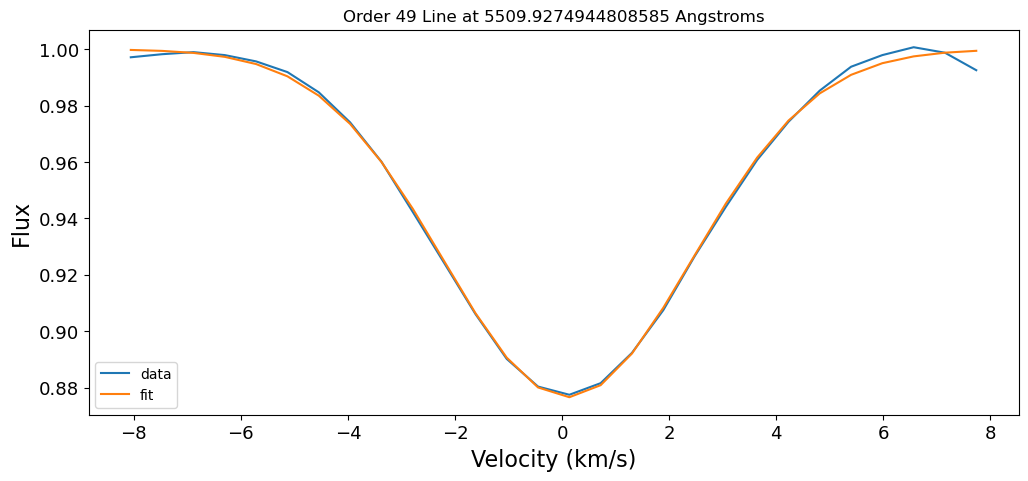

['lambda', 'depth', 'line_id']
5 5510.141195758091 0.11863937854976107
5 5510.141195758091 4987
[[Model]]
    Model(gaussian_w_slope)
[[Fit Statistics]]
    # fitting method   = leastsq
    # function evals   = 49
    # data points      = 28
    # variables        = 5
    chi-square         = 2.1713e-04
    reduced chi-square = 9.4406e-06
    Akaike info crit   = -319.481526
    Bayesian info crit = -312.820503
    R-squared          = 0.96979596
[[Variables]]
    amp:   -0.61018810 +/- 0.04003561 (6.56%) (init = -5.08393)
    cen:    0.53833127 +/- 0.09227043 (17.14%) (init = 0)
    wid:    2.29446185 +/- 0.11742172 (5.12%) (init = 2.299852)
    bas:    0.99990703 +/- 0.00290561 (0.29%) (init = 0)
    slope: -1.0548e-06 +/- 3.6356e-04 (34468.69%) (init = 0)
[[Correlations]] (unreported correlations are < 0.100)
    C(amp, bas)   = -0.8833
    C(amp, wid)   = -0.8437
    C(wid, bas)   = +0.7115
    C(cen, slope) = +0.5038
    C(amp, slope) = -0.2966
    C(bas, slope) = +0.2796
    C(wi

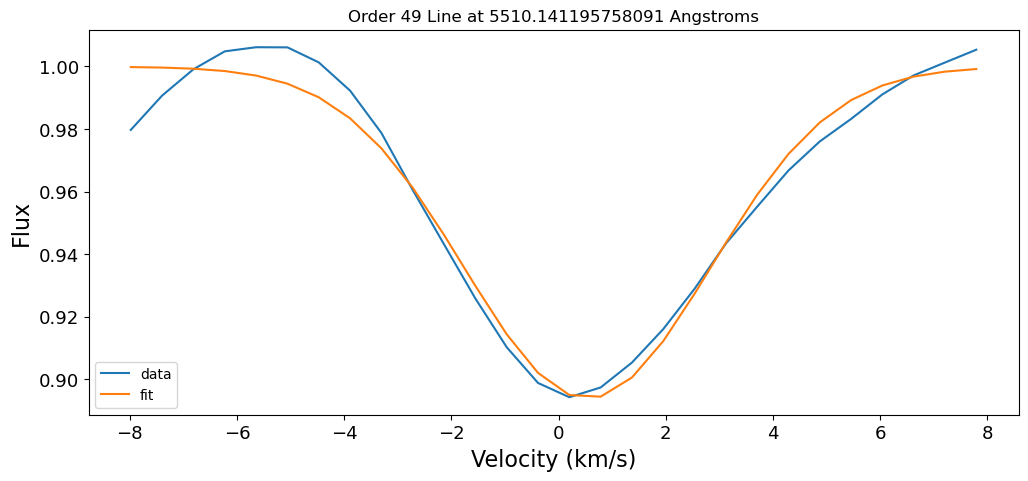

['lambda', 'depth', 'line_id']
6 5513.781385991351 0.2490474822986517
6 5513.781385991351 4990
[[Model]]
    Model(gaussian_w_slope)
[[Fit Statistics]]
    # fitting method   = leastsq
    # function evals   = 37
    # data points      = 29
    # variables        = 5
    chi-square         = 5.4080e-04
    reduced chi-square = 2.2534e-05
    Akaike info crit   = -305.802699
    Bayesian info crit = -298.966220
    R-squared          = 0.99219219
[[Variables]]
    amp:   -1.33775813 +/- 0.03918859 (2.93%) (init = -9.866823)
    cen:   -0.21613765 +/- 0.03631121 (16.80%) (init = 0)
    wid:    2.03293810 +/- 0.04685180 (2.30%) (init = 2.039267)
    bas:    0.99973547 +/- 0.00324578 (0.32%) (init = 0)
    slope: -1.8626e-05 +/- 4.4175e-04 (2371.71%) (init = 0)
[[Correlations]] (unreported correlations are < 0.100)
    C(amp, bas)   = -0.8612
    C(amp, wid)   = -0.8475
    C(wid, bas)   = +0.6406
    C(cen, slope) = +0.4315
    C(bas, slope) = -0.3114
    C(amp, slope) = +0.2767
    C(wid

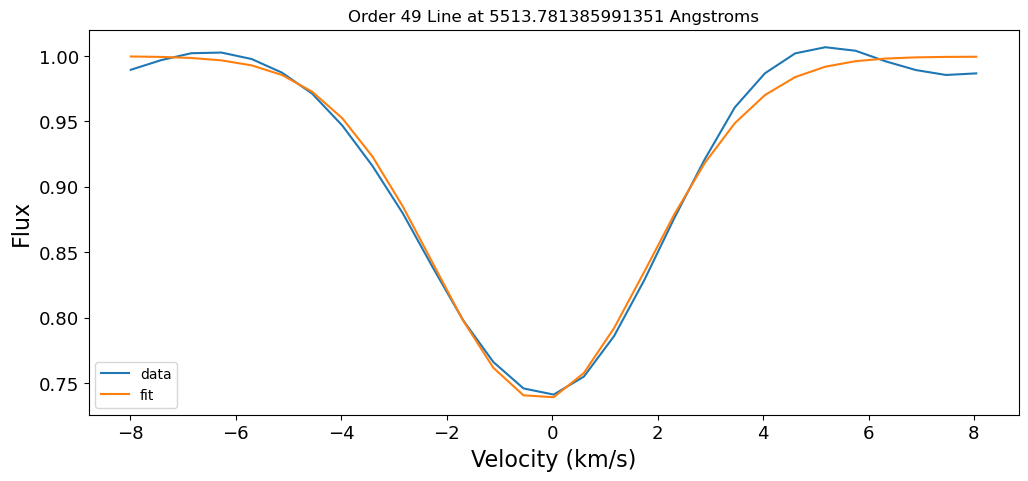

['lambda', 'depth', 'line_id']
7 5514.050473544801 0.34738223986482764
7 5514.050473544801 4991
[[Model]]
    Model(gaussian_w_slope)
[[Fit Statistics]]
    # fitting method   = leastsq
    # function evals   = 31
    # data points      = 28
    # variables        = 5
    chi-square         = 2.2498e-04
    reduced chi-square = 9.7816e-06
    Akaike info crit   = -318.488025
    Bayesian info crit = -311.827002
    R-squared          = 0.99800573
[[Variables]]
    amp:   -1.83047597 +/- 0.02901664 (1.59%) (init = -12.77542)
    cen:    0.07776526 +/- 0.01833380 (23.58%) (init = 0)
    wid:    2.18675681 +/- 0.02501883 (1.14%) (init = 2.185239)
    bas:    1.00003119 +/- 0.00238424 (0.24%) (init = 0)
    slope: -1.3529e-05 +/- 3.1291e-04 (2312.93%) (init = 0)
[[Correlations]] (unreported correlations are < 0.100)
    C(amp, bas)   = -0.9021
    C(amp, wid)   = -0.8833
    C(wid, bas)   = +0.7065
    C(cen, slope) = +0.5166
    C(bas, slope) = +0.3166
    C(amp, slope) = -0.2683
    C(am

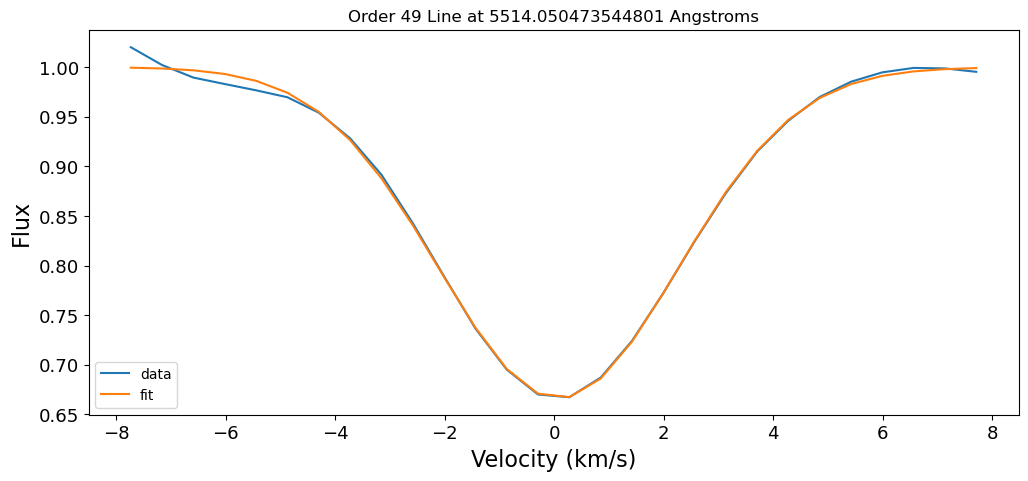

['lambda', 'depth', 'line_id']
8 5514.5070741219515 0.5205270631244967
8 5514.5070741219515 4992
[[Model]]
    Model(gaussian_w_slope)
[[Fit Statistics]]
    # fitting method   = leastsq
    # function evals   = 31
    # data points      = 29
    # variables        = 5
    chi-square         = 2.0346e-04
    reduced chi-square = 8.4774e-06
    Akaike info crit   = -334.153024
    Bayesian info crit = -327.316545
    R-squared          = 0.99958204
[[Variables]]
    amp:   -4.15440284 +/- 0.04581542 (1.10%) (init = -17.73044)
    cen:   -0.08634989 +/- 0.01067693 (12.36%) (init = 0)
    wid:    2.96107543 +/- 0.01819914 (0.61%) (init = 2.960103)
    bas:    1.00014044 +/- 0.00320599 (0.32%) (init = 0)
    slope: -1.6655e-06 +/- 3.0762e-04 (18470.43%) (init = 0)
[[Correlations]] (unreported correlations are < 0.100)
    C(amp, bas)   = -0.9693
    C(amp, wid)   = -0.9498
    C(wid, bas)   = +0.8616
    C(cen, slope) = +0.7518


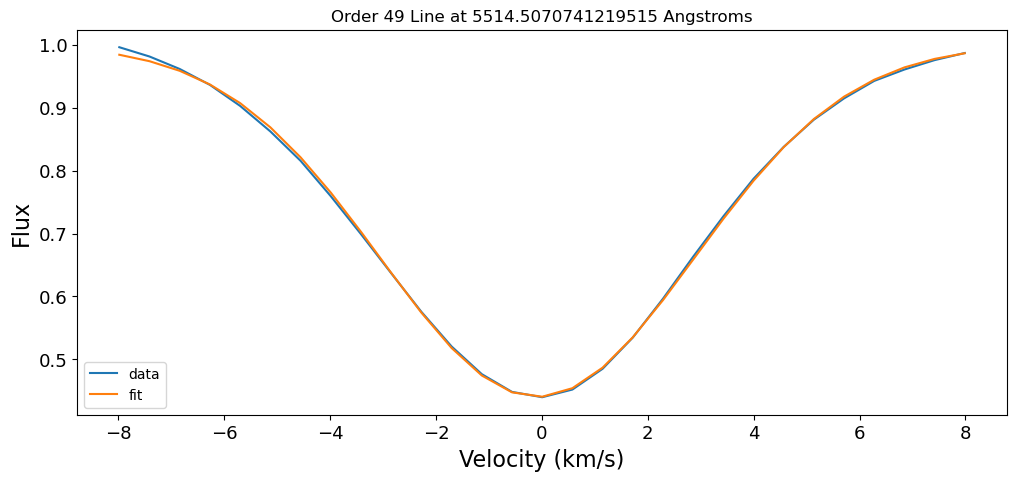

['lambda', 'depth', 'line_id']
9 5515.869416212336 0.300229597471207
9 5515.869416212336 4993
[[Model]]
    Model(gaussian_w_slope)
[[Fit Statistics]]
    # fitting method   = leastsq
    # function evals   = 49
    # data points      = 29
    # variables        = 5
    chi-square         = 0.00512329
    reduced chi-square = 2.1347e-04
    Akaike info crit   = -240.596367
    Bayesian info crit = -233.759888
    R-squared          = 0.93986995
[[Variables]]
    amp:   -1.31829716 +/- 0.10867156 (8.24%) (init = -12.04909)
    cen:   -0.18230752 +/- 0.09802553 (53.77%) (init = 0)
    wid:    1.89144559 +/- 0.12570412 (6.65%) (init = 1.901162)
    bas:    0.99960867 +/- 0.00955479 (0.96%) (init = 0)
    slope: -8.1812e-05 +/- 0.00135500 (1656.25%) (init = 0)
[[Correlations]] (unreported correlations are < 0.100)
    C(amp, bas)   = -0.8428
    C(amp, wid)   = -0.8384
    C(wid, bas)   = +0.6058
    C(cen, slope) = +0.3938
    C(bas, slope) = -0.2316
    C(amp, slope) = +0.2079
    C(wid,

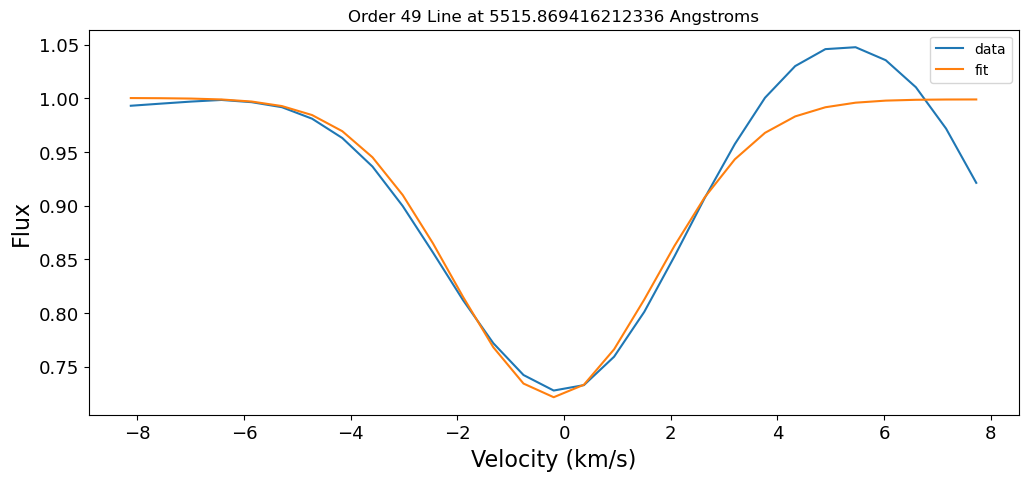

['lambda', 'depth', 'line_id']
10 5516.05980972038 0.3540605364755198
10 5516.05980972038 4994
[[Model]]
    Model(gaussian_w_slope)
[[Fit Statistics]]
    # fitting method   = leastsq
    # function evals   = 43
    # data points      = 29
    # variables        = 5
    chi-square         = 0.00293723
    reduced chi-square = 1.2238e-04
    Akaike info crit   = -256.729964
    Bayesian info crit = -249.893485
    R-squared          = 0.97525991
[[Variables]]
    amp:   -1.77312312 +/- 0.09390873 (5.30%) (init = -13.94788)
    cen:    0.14753079 +/- 0.06145104 (41.65%) (init = 0)
    wid:    2.08195435 +/- 0.08284048 (3.98%) (init = 2.090326)
    bas:    0.99947939 +/- 0.00793296 (0.79%) (init = 0)
    slope:  4.0085e-05 +/- 0.00106883 (2666.39%) (init = 0)
[[Correlations]] (unreported correlations are < 0.100)
    C(amp, bas)   = -0.8806
    C(amp, wid)   = -0.8686
    C(wid, bas)   = +0.6611
    C(cen, slope) = +0.4645
    C(bas, slope) = +0.1974
    C(amp, slope) = -0.1812
    C(wid

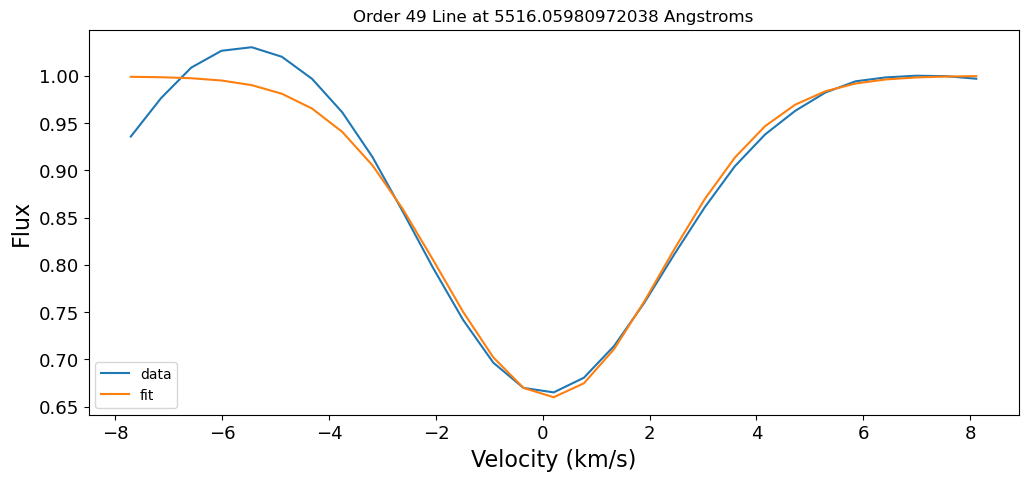

['lambda', 'depth', 'line_id']
11 5518.592282417049 0.1394168130352646
11 5518.592282417049 4996
[[Model]]
    Model(gaussian_w_slope)
[[Fit Statistics]]
    # fitting method   = leastsq
    # function evals   = 31
    # data points      = 29
    # variables        = 5
    chi-square         = 7.7377e-06
    reduced chi-square = 3.2240e-07
    Akaike info crit   = -428.964395
    Bayesian info crit = -422.127916
    R-squared          = 0.99939244
[[Variables]]
    amp:   -0.86838920 +/- 0.00747897 (0.86%) (init = -6.227407)
    cen:    0.04947521 +/- 0.01191351 (24.08%) (init = 0)
    wid:    2.32285101 +/- 0.01537364 (0.66%) (init = 2.323121)
    bas:    0.99999290 +/- 5.5261e-04 (0.06%) (init = 0)
    slope: -2.2907e-09 +/- 6.7836e-05 (2961374.27%) (init = 0)
[[Correlations]] (unreported correlations are < 0.100)
    C(amp, bas)   = -0.8912
    C(amp, wid)   = -0.8565
    C(wid, bas)   = +0.7186
    C(cen, slope) = +0.5145


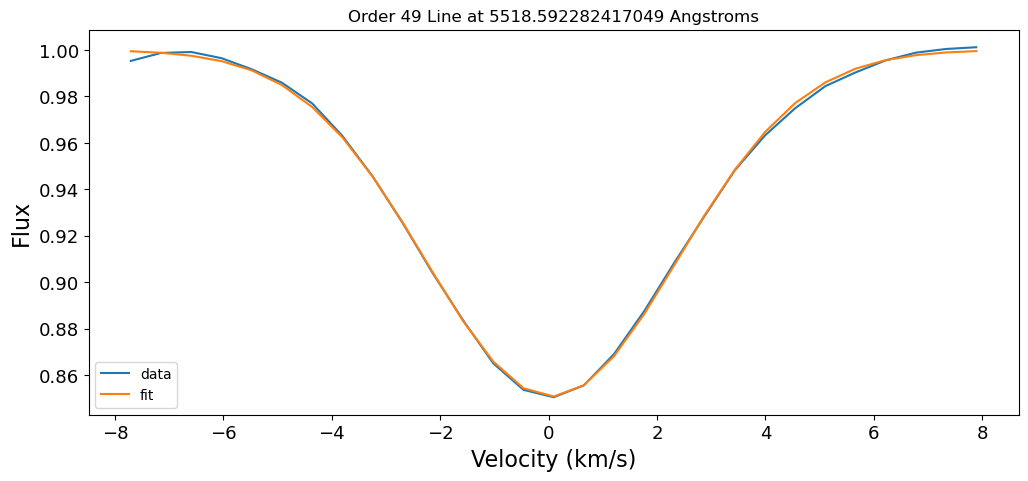

Fitting 12 lines for index 0001 between 3796.7 and 8223.6 Angstroms
Now fitting for NEID...
['lambda', 'depth', 'line_id']
0 5502.992958973535 0.7273424558592381
0 5502.992958973535 4980
[[Model]]
    Model(gaussian_w_slope)
[[Fit Statistics]]
    # fitting method   = leastsq
    # function evals   = 25
    # data points      = 31
    # variables        = 5
    chi-square         = 8.3028e-04
    reduced chi-square = 3.1934e-05
    Akaike info crit   = -316.359734
    Bayesian info crit = -309.189798
    R-squared          = 0.99947520
[[Variables]]
    amp:   -6.06422804 +/- 0.09559251 (1.58%) (init = -22.91282)
    cen:   -0.10289376 +/- 0.01263678 (12.28%) (init = 0)
    wid:    3.29896136 +/- 0.02462727 (0.75%) (init = 3.299644)
    bas:    0.99980698 +/- 0.00652245 (0.65%) (init = 0)
    slope: -2.0821e-06 +/- 5.4941e-04 (26387.65%) (init = 0)
[[Correlations]] (unreported correlations are < 0.100)
    C(amp, bas)   = -0.9847
    C(amp, wid)   = -0.9685
    C(wid, bas)   = +0.9136


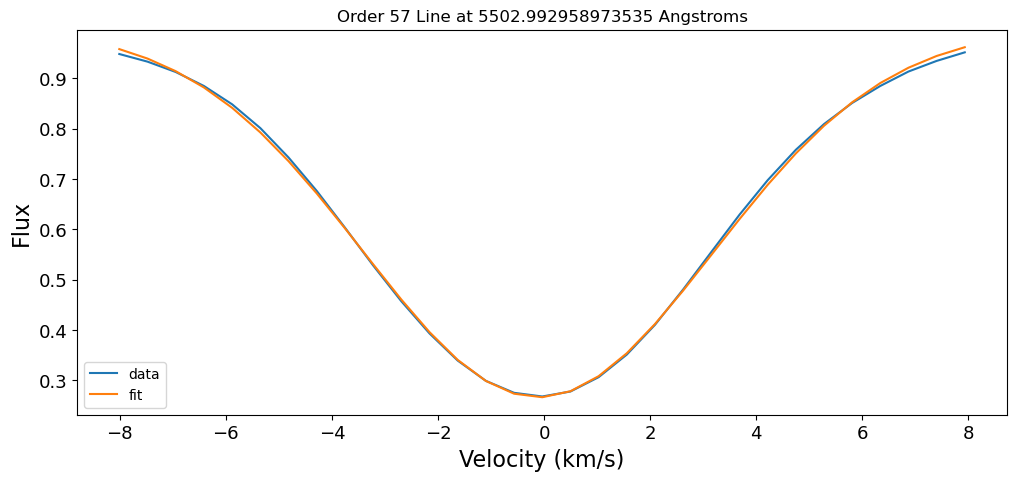

[[Model]]
    Model(gaussian_w_slope)
[[Fit Statistics]]
    # fitting method   = leastsq
    # function evals   = 25
    # data points      = 23
    # variables        = 5
    chi-square         = 5.1733e-04
    reduced chi-square = 2.8741e-05
    Akaike info crit   = -236.153457
    Bayesian info crit = -230.475986
    R-squared          = 0.99958732
[[Variables]]
    amp:   -6.03204767 +/- 0.10582027 (1.75%) (init = -16.93309)
    cen:   -0.10283235 +/- 0.01406425 (13.68%) (init = 0)
    wid:    3.30046363 +/- 0.02746184 (0.83%) (init = 3.300959)
    bas:    0.99985379 +/- 0.00721107 (0.72%) (init = 0)
    slope: -2.5307e-06 +/- 6.0392e-04 (23864.14%) (init = 0)
[[Correlations]] (unreported correlations are < 0.100)
    C(amp, bas)   = -0.9849
    C(amp, wid)   = -0.9690
    C(wid, bas)   = +0.9148
    C(cen, slope) = +0.8739


KeyboardInterrupt: 

In [33]:
fit_results=[]
#loop through the overlapping indices and fit lines to the NEID and EXPRES coadds
for i,idx in enumerate(neid_indices[:3]):

    w_NEID=np.array(data['NEID']['wls'][idx])
    s_NEID=np.array(data['NEID']['coadds'][idx])
    e_NEID=np.array(data['NEID']['uncs'][idx])

    w_EXPRES=np.array(data['EXPRES']['wls'][idx])
    s_EXPRES=np.array(data['EXPRES']['coadds'][idx])
    e_EXPRES=np.array(data['EXPRES']['uncs'][idx])

    upper=np.min((np.max(w_NEID),np.max(w_EXPRES)))
    lower=np.max((np.min(w_NEID),np.min(w_EXPRES)))

    #find line fits in both spectra that are at least 500 pixels from the edge of at least one order
    lines_to_use={}

    cols_to_keep=['lambda','depth','line_id']
    for col in cols_to_keep:
        lines_to_use[col]=[]
    for row in line_list:
        l=row['lambda']
    
        if l<5520 and l>5500:
            #find all the orders that contain this wavelength, and the line is more than 500 pixels from the edge of the order  
            #if line is not atleast 500 pixels from the edge of at least one order in both NEID and EXPRES, include it in lines_to_use
            neid_ok=False
            expres_ok=False
            for o in range(w_NEID.shape[0]):
                if l>w_NEID[o].min()+dist_from_edge*(w_NEID[o][1]-w_NEID[o][0]) and l<w_NEID[o].max()-dist_from_edge*(w_NEID[o][1]-w_NEID[o][0]):
                    neid_ok=True
            for o in range(w_EXPRES.shape[0]):
                if l>w_EXPRES[o].min()+dist_from_edge*(w_EXPRES[o][1]-w_EXPRES[o][0]) and l<w_EXPRES[o].max()-dist_from_edge*(w_EXPRES[o][1]-w_EXPRES[o][0]):
                    expres_ok=True
            if neid_ok and expres_ok:
                for col in cols_to_keep:
                    lines_to_use[col].append(row[col])
    lines_to_use=Table(lines_to_use)

    #print number of fitting lines for index idx
    #print(lines_to_use)
    print(f"Fitting {len(lines_to_use)} lines for index {idx} between {lower:.1f} and {upper:.1f} Angstroms")
    print("Now fitting for NEID...")
    line_fits_NEID=fit_lines(w_NEID,s_NEID,e_NEID,lines_to_use,plot=True,wl_min=lower,wl_max=upper,fit_range=0.15,dist_from_edge=500,plotbad=True)
    print("Now fitting for EXPRES...")
    line_fits_EXPRES=fit_lines(w_EXPRES,s_EXPRES,e_EXPRES,lines_to_use,plot=True,wl_min=lower,wl_max=upper,fit_range=0.15,dist_from_edge=500,plotbad=True)
    fit_results.append({'index':idx,'NEID_fits':line_fits_NEID,'EXPRES_fits':line_fits_EXPRES,'overlap_mid':overlap_mids[i]})
    #

In [ ]:
fit_results

In [ ]:
def get_fit_results(data,neid_indices,line_list,fit_range,plot=False,plotbad=False,test=False,testnum=0,dist_from_edge=500):
    fit_results=[]
#loop through the overlapping indices and fit lines to the NEID and EXPRES coadds
    for i,idx in enumerate(neid_indices[testnum:]):
    
        w_NEID=np.array(data['NEID']['wls'][idx])
        s_NEID=np.array(data['NEID']['coadds'][idx])
        e_NEID=np.array(data['NEID']['uncs'][idx])
    
        w_EXPRES=np.array(data['EXPRES']['wls'][idx])
        s_EXPRES=np.array(data['EXPRES']['coadds'][idx])
        e_EXPRES=np.array(data['EXPRES']['uncs'][idx])
    
        upper=np.min((np.max(w_NEID),np.max(w_EXPRES)))
        lower=np.max((np.min(w_NEID),np.min(w_EXPRES)))
    
        #find line fits in both spectra that are at least 500 pixels from the edge of at least one order
        lines_to_use={}
    
        cols_to_keep=['lambda','depth']
        for col in cols_to_keep:
            lines_to_use[col]=[]
        for row in line_list:
            l=row['lambda']
        
            if l<upper and l>lower:
                #find all the orders that contain this wavelength, and the line is more than 500 pixels from the edge of the order  
                #if line is not atleast 500 pixels from the edge of at least one order in both NEID and EXPRES, include it in lines_to_use
                neid_ok=False
                expres_ok=False
                for o in range(w_NEID.shape[0]):
                    if l>w_NEID[o].min()+dist_from_edge*(w_NEID[o][1]-w_NEID[o][0]) and l<w_NEID[o].max()-dist_from_edge*(w_NEID[o][1]-w_NEID[o][0]):
                        neid_ok=True
                for o in range(w_EXPRES.shape[0]):
                    if l>w_EXPRES[o].min()+dist_from_edge*(w_EXPRES[o][1]-w_EXPRES[o][0]) and l<w_EXPRES[o].max()-dist_from_edge*(w_EXPRES[o][1]-w_EXPRES[o][0]):
                        expres_ok=True
                if neid_ok and expres_ok:
                    for col in cols_to_keep:
                        lines_to_use[col].append(row[col])
        lines_to_use=Table(lines_to_use)
    
        #print number of fitting lines for index idx
        #print(lines_to_use)
        print(f"Fitting {len(lines_to_use)} lines for index {idx} between {lower:.1f} and {upper:.1f} Angstroms")
        print("Now fitting for NEID...")
        line_fits_NEID=fit_lines(w_NEID,s_NEID,e_NEID,lines_to_use,plot=plot,wl_min=lower,wl_max=upper,fit_range=fit_range,dist_from_edge=dist_from_edge,plotbad=plotbad)
        if test==False:
            print("Now fitting for EXPRES...")
            line_fits_EXPRES=fit_lines(w_EXPRES,s_EXPRES,e_EXPRES,lines_to_use,plot=plot,wl_min=lower,wl_max=upper,fit_range=fit_range,dist_from_edge=dist_from_edge,plotbad=plotbad)
            fit_results.append({'index':idx,'NEID_fits':line_fits_NEID,'EXPRES_fits':line_fits_EXPRES,'overlap_mid':overlap_mids[i]})
            #
        else:
            fit_results.append(line_fits_NEID)
    return fit_results


In [ ]:
fit_test_rangep15=get_fit_results(data,neid_indices,line_list,fit_range=.15, test=True,testnum=-1)
fit_test_rangep1=get_fit_results(data,neid_indices,line_list,fit_range=.1, test=True,testnum=-1)
fit_test_rangep15_dist800=get_fit_results(data,neid_indices,line_list,fit_range=.15, test=True,testnum=-1,dist_from_edge=800)

In [ ]:
fit_test_rangep05=get_fit_results(data,neid_indices,line_list,fit_range=.05, test=True,testnum=-1)

In [ ]:
fit_test_rangep15_dist400=get_fit_results(data,neid_indices,line_list,fit_range=.15, test=True,testnum=-1,dist_from_edge=400)
fit_test_rangep15_dist300=get_fit_results(data,neid_indices,line_list,fit_range=.15, test=True,testnum=-1,dist_from_edge=300)
fit_test_rangep15_dist200=get_fit_results(data,neid_indices,line_list,fit_range=.15, test=True,testnum=-1,dist_from_edge=200)

In [ ]:
fit_test_rangep7=get_fit_results(data,neid_indices,line_list,fit_range=.7, test=True,testnum=-1)

In [ ]:
bins=np.arange(201)/100-1
bins

In [ ]:

rs=[item['r'] for item in fit_test_rangep15[0]]
rs_p1=[item['r'] for item in fit_test_rangep1[0]]
rs_p05=[item['r'] for item in fit_test_rangep05[0]]
rs_p7=[item['r'] for item in fit_test_rangep7[0]]
rs_e800=[item['r'] for item in fit_test_rangep15_dist800[0]]
rs_e400=[item['r'] for item in fit_test_rangep15_dist400[0]]
rs_e300=[item['r'] for item in fit_test_rangep15_dist300[0]]
rs_e200=[item['r'] for item in fit_test_rangep15_dist200[0]]
plt.hist(rs,alpha=.4,bins=bins)
plt.hist(rs_p1,alpha=.4,bins=bins)
plt.hist(rs_p05,alpha=.4,bins=bins)
plt.hist(rs_p7,alpha=.4,bins=bins)
#plt.hist(rs_e800,alpha=.4,bins=bins)
plt.xlim(0,1)

In [ ]:

rs=[item['r'] for item in fit_test_rangep15[0]]
rs_p1=[item['r'] for item in fit_test_rangep1[0]]
rs_p05=[item['r'] for item in fit_test_rangep05[0]]
rs_p7=[item['r'] for item in fit_test_rangep7[0]]
rs_e800=[item['r'] for item in fit_test_rangep15_dist800[0]]
rs_e400=[item['r'] for item in fit_test_rangep15_dist400[0]]
rs_e300=[item['r'] for item in fit_test_rangep15_dist300[0]]
rs_e200=[item['r'] for item in fit_test_rangep15_dist200[0]]
#plt.hist(rs,alpha=.4,bins=bins)
plt.hist(rs_p1,alpha=.4,bins=bins)
plt.hist(rs_p05,alpha=.4,bins=bins)
#plt.hist(rs_p7,alpha=.4,bins=bins)
#plt.hist(rs_e800,alpha=.4,bins=bins)
plt.xlim(0,1)

In [ ]:

rs=[item['r'] for item in fit_test_rangep15[0]]
rs_p1=[item['r'] for item in fit_test_rangep1[0]]
rs_p7=[item['r'] for item in fit_test_rangep7[0]]
rs_e800=[item['r'] for item in fit_test_rangep15_dist800[0]]
plt.hist(rs,alpha=.4,bins=bins)
#plt.hist(rs_p1,alpha=.4,bins=bins)
#plt.hist(rs_p7,alpha=.4,bins=bins)
#plt.hist(rs_e800,alpha=.4,bins=bins)
plt.hist(rs_e400,alpha=.4,bins=bins)
#plt.hist(rs_e300,alpha=.4,bins=bins)
#plt.hist(rs_e200,alpha=.4,bins=bins)
plt.xlim(0,1)

In [ ]:

rs=[item['r'] for item in fit_test_rangep15[0]]
rs_p1=[item['r'] for item in fit_test_rangep1[0]]
rs_p7=[item['r'] for item in fit_test_rangep7[0]]
rs_e800=[item['r'] for item in fit_test_rangep15_dist800[0]]
#plt.hist(rs,alpha=.4,bins=bins)
#plt.hist(rs_p1,alpha=.4,bins=bins)
#plt.hist(rs_p7,alpha=.4,bins=bins)
#plt.hist(rs_e800,alpha=.4,bins=bins)
plt.hist(rs_e400,alpha=.4,bins=bins)
plt.hist(rs_e300,alpha=.4,bins=bins)
plt.hist(rs_e200,alpha=.4,bins=bins)
plt.xlim(0,1)

In [ ]:
fit_results=get_fit_results(data,neid_indices,line_list,fit_range=0.1,dis)

In [ ]:
#save fit results to pickele file

with open('line_fit_results_neid_expres_overlap_2024_w_werr.pkl','wb') as f:
    pickle.dump(fit_results,f)